# Viande et masculinité
## Existe-t-il une corrélation entre les normes de genre et la consommation de viande rouge en Europe ?

**Projet de data science - ENSAE Paris, 2A**

 Solène Pinguet - Noriane Ménard - Emna Larbi · *Date : 24/11/2026*

---

### Résumé
Le samedi 27 août 2022, lors d'une table ronde des journées d'été d'Europe Écologie Les Verts, Sandrine Rousseau a prononcé cette phrase marquante "Il faut changer de mentalité pour que manger une entrecôte cuite sur un barbecue ne soit plus un symbole de virilité". Sa récente proposition de taxer les produits carnés transformés et les réactions que cela a suscitées, nous ont poussées à nous interroger sur le lien entre virilité perçue et consommation de viande rouge. Ainsi, nous nous sommes demandées s'il existait une corrélation entre ces deux variables. Le concept de virilité est illustré par le sentiment de masculinité ressenti. Notre étude se concentre sur certains pays européens. 

### Plan
1. [Configuration](#1.-Configuration)
2. [Les données](#sec-2)
3. [Statistiques descriptives](#3.-Statistiques-descriptives)
4. [Cartographie](#4.-Cartographie)
5. [Régressions](#sec-5)
6. [Discussion et conclusion](#6.-Discussion-et-conclusion)
7. [Annexe : reproductibilité](#sec-7)

## 1. Configuration

Le notebook **affiche et commente** ; les calculs sont faits par les scripts de `Src/`, importés ci-dessous.
Avec `RECALCULER = False`, le notebook lit les fichiers déjà produits dans `Data/processed/` (exécution rapide).
Avec `RECALCULER = True`, il relance la chaîne complète depuis `Data/raw/`.

In [ ]:
import subprocess
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.iolib.summary2 import summary_col
from statsmodels.stats.outliers_influence import variance_inflation_factor
from IPython.display import Image, Markdown, display

RACINE = Path.cwd()
if not (RACINE / "Src").exists():
    RACINE = next(p for p in [RACINE, *RACINE.parents] if (p / "Src").exists())
SRC = RACINE / "Src"
RAW = RACINE / "Data" / "raw"
PROCESSED = RACINE / "Data" / "processed"
sys.path.insert(0, str(SRC))

RECALCULER = False          # True : relance le nettoyage, la jointure et les cartes
GRAINE = 2020
np.random.seed(GRAINE)

pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.family": "serif"})
warnings.filterwarnings("ignore", category=FutureWarning)

print("Racine du projet :", RACINE)

ModuleNotFoundError: No module named 'matplotlib'

In [ ]:
# Chaîne de traitement complète (uniquement si RECALCULER = True), dans l'ordre d'exécution.
ETAPES = ["data_upload.py", "import_clean.py", "merge.py", "stats_descriptives.py",
          "maps.py", "carte_masculinite.py", "regression.py"]

if RECALCULER:
    for script in ETAPES:
        print(f"▶ {script}")
        subprocess.run([sys.executable, str(SRC / script)], cwd=RACINE, check=True)
else:
    print("Lecture des fichiers déjà produits dans Data/processed/")

In [ ]:
import re
from IPython.display import Image, display

# Dossier des sorties des scripts de Src/ (cherché automatiquement dans le projet)
SORTIES = RACINE / "sorties"
if not SORTIES.exists():
    SORTIES = next(p for p in RACINE.rglob("sorties") if p.is_dir())
print("Sorties :", SORTIES)


def lire_tableau_tex(chemin) -> pd.DataFrame:
    """Lit le tableau `tabular` d'un fichier .tex et le renvoie en DataFrame
    (Jupyter et GitHub n'affichent pas le LaTeX des tableaux)."""
    tex = Path(chemin).read_text(encoding="utf-8")
    m = re.search(r"\\begin\{tabular\}\{.*?\}(.*?)\\end\{tabular\}", tex, flags=re.S)
    if m is None:
        raise ValueError(f"Aucun tableau dans {chemin}")
    corps = re.sub(r"\\(?:toprule|midrule|bottomrule|hline|cline\{[^}]*\})", "", m.group(1))
    corps = re.sub(r"\\(?:textbf|textit|emph|text)\{([^}]*)\}", r"\1", corps)
    corps = re.sub(r"\\multicolumn\{\d+\}\{[^}]*\}\{([^}]*)\}", r"\1", corps)
    corps = re.sub(r"\$\^\{([^}]*)\}\$", r"\1", corps)
    corps = corps.replace(r"\_", "_").replace(r"\%", "%").replace("$", "").replace("{}", "")
    lignes = [l.strip() for l in re.split(r"\\\\", corps) if l.strip()]
    cellules = [[c.strip() for c in l.split("&")] for l in lignes]
    n = max(len(r) for r in cellules)
    cellules = [r + [""] * (n - len(r)) for r in cellules]
    df = pd.DataFrame(cellules[1:], columns=cellules[0])
    return df.set_index(df.columns[0]).rename_axis(None)


def afficher_sortie(nom: str, largeur: int = 800) -> None:
    """Affiche une sortie d'un script de Src/ : tableau .tex ou image .png."""
    chemin = SORTIES / nom
    if not chemin.exists():
        print(f"Sortie absente : {chemin.name} — relancer la chaîne avec RECALCULER = True "
              f"(ou le script de Src/ qui produit ce fichier)")
    elif chemin.suffix == ".tex":
        display(lire_tableau_tex(chemin))
    else:
        display(Image(chemin, width=largeur))

<a id="sec-2"></a>
## 2. Les données

### 2.1 Sources

| Source | Terrain | Contenu utilisé | Unité | Pondération | Accès |
|---|---|---|---|---|---|
| ISSP 2020, *Environment IV* | 2019-2023 (surtout 2020-2021) | jours de consommation de bœuf ou d'agneau | individu | `WEIGHT` | fichier `.dta` (GESIS) |
| ESS, vague 11 | 2023-2024 | masculinité ressentie (`mascfel`) | individu | `anweight` | fichier `.csv` (ESS) |
| Banque mondiale, *World Development Indicators* | 2022 | PIB par habitant en PPA | pays | - | API, `Src/data_upload.py` |

### 2.2 Variables

| Variable | Source | Question / définition | Échelle |
|---|---|---|---|
| `jours_viande_rouge` | ISSP (`v50`) | « Typical week: number of days that you eat beef/lamb? » | 0-7 jours |
| `ecart_h_f` | ISSP (calculée) | moyenne pondérée des hommes − moyenne pondérée des femmes | jours par semaine |
| `mascfel` | ESS | « À quel point vous sentez-vous masculin ? » | 0-6 |
| `mascfel_homme_w`, `mascfel_femme_w` | ESS (calculées) | moyennes par pays et par sexe, pondérées par `anweight` | 0-6 |
| `ecart_masc_h_f` | calculée | `mascfel_homme_w − mascfel_femme_w` | points |
| `pib_hab` | Banque mondiale | PIB par habitant en PPA, dollars internationaux constants de 2021, année 2022, utilisé en logarithme | $ PPA |

### 2.3 Nettoyage

Les deux enquêtes sont nettoyées par `Src/import_clean.py`, qui les traite séparément puis les agrège au niveau
des pays. Le PIB par habitant est récupéré par `Src/data_upload.py`. Les fichiers produits sont enregistrés dans
`Data/processed/`.

#### ISSP 2020 : consommation de viande rouge

**Variables retenues.** Cinq variables sont chargées depuis `ISSP_2020.dta` :

| Variable brute | Renommée en | Contenu |
|---|---|---|
| `c_alphan` | `country_iso2` | code pays ISO à deux lettres |
| `country` | `country_code` | code pays numérique ISSP |
| `SEX` | `sexe` | sexe du répondant |
| `v50` | `jours_viande_rouge` | nombre de jours, dans une semaine type, où le répondant mange du bœuf ou de l'agneau (fréquence déclarée, pas une quantité) |
| `WEIGHT` | `poids` | poids statistique individuel |

La question ne porte que sur le bœuf et l'agneau : le porc et la volaille ne sont pas mesurés. C'est en ce sens
restreint que l'on parle ici de « viande rouge ».

**Codes de non-réponse.** Dans l'ISSP, les codes négatifs ne sont pas des réponses :
- les répondants végétariens (code −4) sont recodés à **0 jour**. Ils ne consomment réellement aucune viande rouge,
  et les exclure aurait surestimé la consommation moyenne. Ce choix compte d'autant plus que les femmes sont plus
  souvent végétariennes : les retirer aurait mécaniquement réduit l'écart entre hommes et femmes ;
- tous les autres codes négatifs (« ne sait pas », refus, non-réponse) sont traités comme **valeurs manquantes** ;
- le sexe est recodé `1 → homme`, `2 → femme` ; toute autre valeur est considérée comme manquante.

Les répondants sans sexe, sans fréquence de consommation ou sans poids sont ensuite retirés, car ils ne peuvent
pas entrer dans le calcul des moyennes par sexe. La base passe de 44 100 à 41 382 répondants (2 718 lignes supprimées).

**Pondération.** Les échantillons ISSP ne sont pas parfaitement représentatifs de la population
(certaines catégories sont sur- ou sous-représentées). Toutes les moyennes sont donc **pondérées** par `WEIGHT` :

$$\bar{x}_{\text{pays, sexe}} = \frac{\sum_i w_i\, x_i}{\sum_i w_i}$$

**Agrégation par pays et par sexe.** Pour chaque pays, on calcule :
- `conso_homme` et `conso_femme` : moyennes pondérées de la fréquence de consommation ;
- `n_homme` et `n_femme` : effectifs **bruts** (non pondérés), qui servent à repérer les petits échantillons ;
- `ecart_h_f = conso_homme − conso_femme` : positif quand les hommes déclarent une fréquence plus élevée.

#### ESS 11 : masculinité ressentie

**Variables retenues.** Quatre variables seulement : le code pays (`cntry`), le sexe (`gndr`), la masculinité
ressentie (`mascfel`) et le poids d'analyse (`anweight`).

**Codes de non-réponse.** Les codes de refus, de « ne sait pas » et de non-réponse sont remplacés par des valeurs
manquantes : 7, 8 et 9 pour `mascfel` (échelle de 0 à 6), 9 pour `gndr`. Les répondants ayant une valeur manquante
sur l'une des quatre variables sont ensuite retirés : 668 lignes sont supprimées et 49 448 répondants sont conservés
sur 50 116.

**Pondération.** Comme pour l'ISSP, les moyennes de masculinité sont pondérées, ici par `anweight`, le poids
d'analyse recommandé par l'ESS (produit du poids de post-stratification `pspwght`, qui corrige l'échantillon selon
l'âge, le sexe, le niveau d'études et la région, et du poids lié à la taille de la population, `pweight`). Sans
pondération, certains échantillons nationaux sont nettement trop âgés : en Autriche, l'âge moyen des hommes
interrogés est de 54 ans, contre 48 ans une fois l'échantillon pondéré.

**Agrégation par pays et par sexe.** Pour chaque pays, on calcule `mascfel_homme_w` et `mascfel_femme_w`, moyennes
**pondérées** de la masculinité ressentie chez les hommes et chez les femmes, avec leurs effectifs bruts
(`n_ess_homme`, `n_ess_femme`), ainsi que la moyenne de `mascfel` sur l'ensemble des répondants. L'agrégation par sexe permet de construire
`ecart_masc_h_f = mascfel_homme_w − mascfel_femme_w`, qui se compare directement à l'écart de consommation de viande.

#### PIB par habitant : API de la Banque mondiale

Le PIB par habitant est récupéré automatiquement par `Src/data_upload.py`,
qui interroge l'API publique de la Banque mondiale (`https://api.worldbank.org/v2`, sans clé d'accès). Le script
demande l'indicateur `NY.GDP.PCAP.PP.KD`, « GDP per capita, PPP (constant 2021 international $) », pour tous les pays
et toutes les années de 1990 à 2025, en parcourant les pages de résultats. On retire ensuite les 79 agrégats (monde, zone euro, groupes de revenu…), qui ne sont pas des pays, puis
supprime les valeurs manquantes. Le résultat, au format long (une ligne par pays et par année : `iso3`, `pays`,
`annee`, `pib_hab_ppa`), couvre 199 pays et est enregistré dans `Data/processed/pib_hab_ppa_banque_mondiale.csv`.
Le script affiche la date de dernière mise à jour des données (11 novembre 2026 lors de notre extraction)
et vérifie que les 15 pays de l'analyse ont une valeur en 2022. Si ce fichier est absent, `Src/merge.py`
appelle lui-même `data_upload.py` pour le télécharger afin de garantir la reproductibilité. 

**Pourquoi la parité de pouvoir d'achat ?** Le PIB en dollars courants convertit les richesses nationales au taux de
change de l'année, qui fluctue (le dollar était particulièrement fort en 2022) et ne tient pas compte des
différences de niveau des prix entre pays. Le PIB en PPA corrige ces différences et mesure donc mieux le niveau de
vie comparé, ce qui correspond à ce que l'on cherche à contrôler. Les écarts de richesse en sont nettement réduits :
en 2022, la Norvège est environ 2,5 fois plus riche que la Slovaquie en PPA, contre plus de 5 fois en dollars courants.

## 3. Statistiques descriptives

In [ ]:
afficher_sortie("statistiques_descriptives.tex")

,N,Moyenne,Écart-type,Min,Max
ecart_viande_h_f,15,0.461000,0.195000,0.049000,0.694000
ecart_masc_h_f,15,4.221000,0.749000,2.630000,5.119000
log_pib,15,10.924000,0.268000,10.562000,11.463000


Sur les 15 pays, l'écart de consommation de viande rouge entre hommes et femmes est **positif partout** :
les hommes en déclarent toujours une fréquence plus élevée. Il varie toutefois beaucoup d'un pays à l'autre
(de 0,05 à 0,69 jour par semaine, moyenne 0,46). L'écart de masculinité ressentie est élevé dans tous les pays
(de 2,6 à 5,1 points, moyenne 4,2) : les identités de genre sont partout très différenciées, à des degrés variables.

Le PIB par habitant en PPA varie d'un facteur d'environ 2,5 (de 38 600$ en Slovaquie à 95 100$ en Norvège,
en dollars internationaux de 2021), ce qui justifie de le contrôler dans les régressions.
Avec seulement 15 pays, un pays atypique peut peser fortement sur les résultats.

In [ ]:
# Tableau par pays (Src/stats_descriptives.py), trié par écart de consommation décroissant.
# Viande H/F : jours par semaine de bœuf ou d'agneau (ISSP, pondéré) ; Masc. H/F : masculinité
# ressentie sur 0-6 (ESS, pondérée par anweight) ; PIB/hab PPA : $ internationaux de 2021, année 2022.
afficher_sortie("tableau_pays.tex")

,Viande H,Viande F,Écart viande,Ratio H/F,Masc. H,Masc. F,Écart masc.,PIB/hab PPA
Suisse,2.59,1.90,0.69,1.37,5.20,1.07,4.13,85762
Finlande,2.94,2.24,0.69,1.31,4.19,1.56,2.63,57068
Norvège,3.04,2.36,0.67,1.29,4.53,1.47,3.06,95110
Suède,2.59,1.96,0.64,1.32,4.64,1.29,3.36,62545
Allemagne,2.16,1.54,0.62,1.40,5.23,0.62,4.61,63778
Islande,3.24,2.68,0.56,1.21,4.85,1.34,3.52,66581
Slovénie,1.95,1.40,0.55,1.40,5.39,1.14,4.25,47059
Italie,2.70,2.24,0.46,1.21,5.60,0.61,4.99,52333
Croatie,2.45,2.02,0.44,1.22,5.25,0.56,4.69,39864
France,2.43,2.08,0.36,1.17,5.52,1.02,4.50,53674


**Lecture du tableau par pays:** Les niveaux de consommation varient bien davantage entre pays qu'entre sexes :
les hommes hongrois mangent du bœuf ou de l'agneau 0,65 jour par semaine, les hommes islandais 3,24 jours, et les
femmes islandaises (2,68) en consomment plus souvent que les hommes de 11 des 14 autres pays de l'échantillon.
Les plus forts écarts entre hommes et femmes se trouvent en Suisse, dans les pays nordiques et en Allemagne
(de 0,62 à 0,69 jour), les plus faibles en Hongrie (0,05), en Lituanie et en Autriche.

Le ratio hommes/femmes ne classe pas les pays de la même façon que l'écart en jours. La Slovaquie, qui n'a qu'un
écart de 0,36 jour, présente le ratio le plus élevé (1,42) : les hommes y mangent du bœuf ou de l'agneau 42 % plus
souvent que les femmes, mais à partir d'un niveau faible (1,20 jour contre 0,85). À l'inverse, l'Islande a un écart
de 0,56 jour mais un ratio de seulement 1,21. L'écart absolu dépend donc en partie du niveau de consommation du pays.

Côté masculinité ressentie, les hommes se situent partout entre 4,2 (Finlande) et 5,6 (Italie) sur l'échelle de 0 à 6,
et les femmes entre 0,3 (Slovaquie) et 1,6 (Finlande). Le faible écart des pays nordiques tient aux deux sexes :
des hommes un peu moins masculins et des femmes un peu plus qu'ailleurs.

## 4. Cartographie

### 4.1 Consommation de viande 

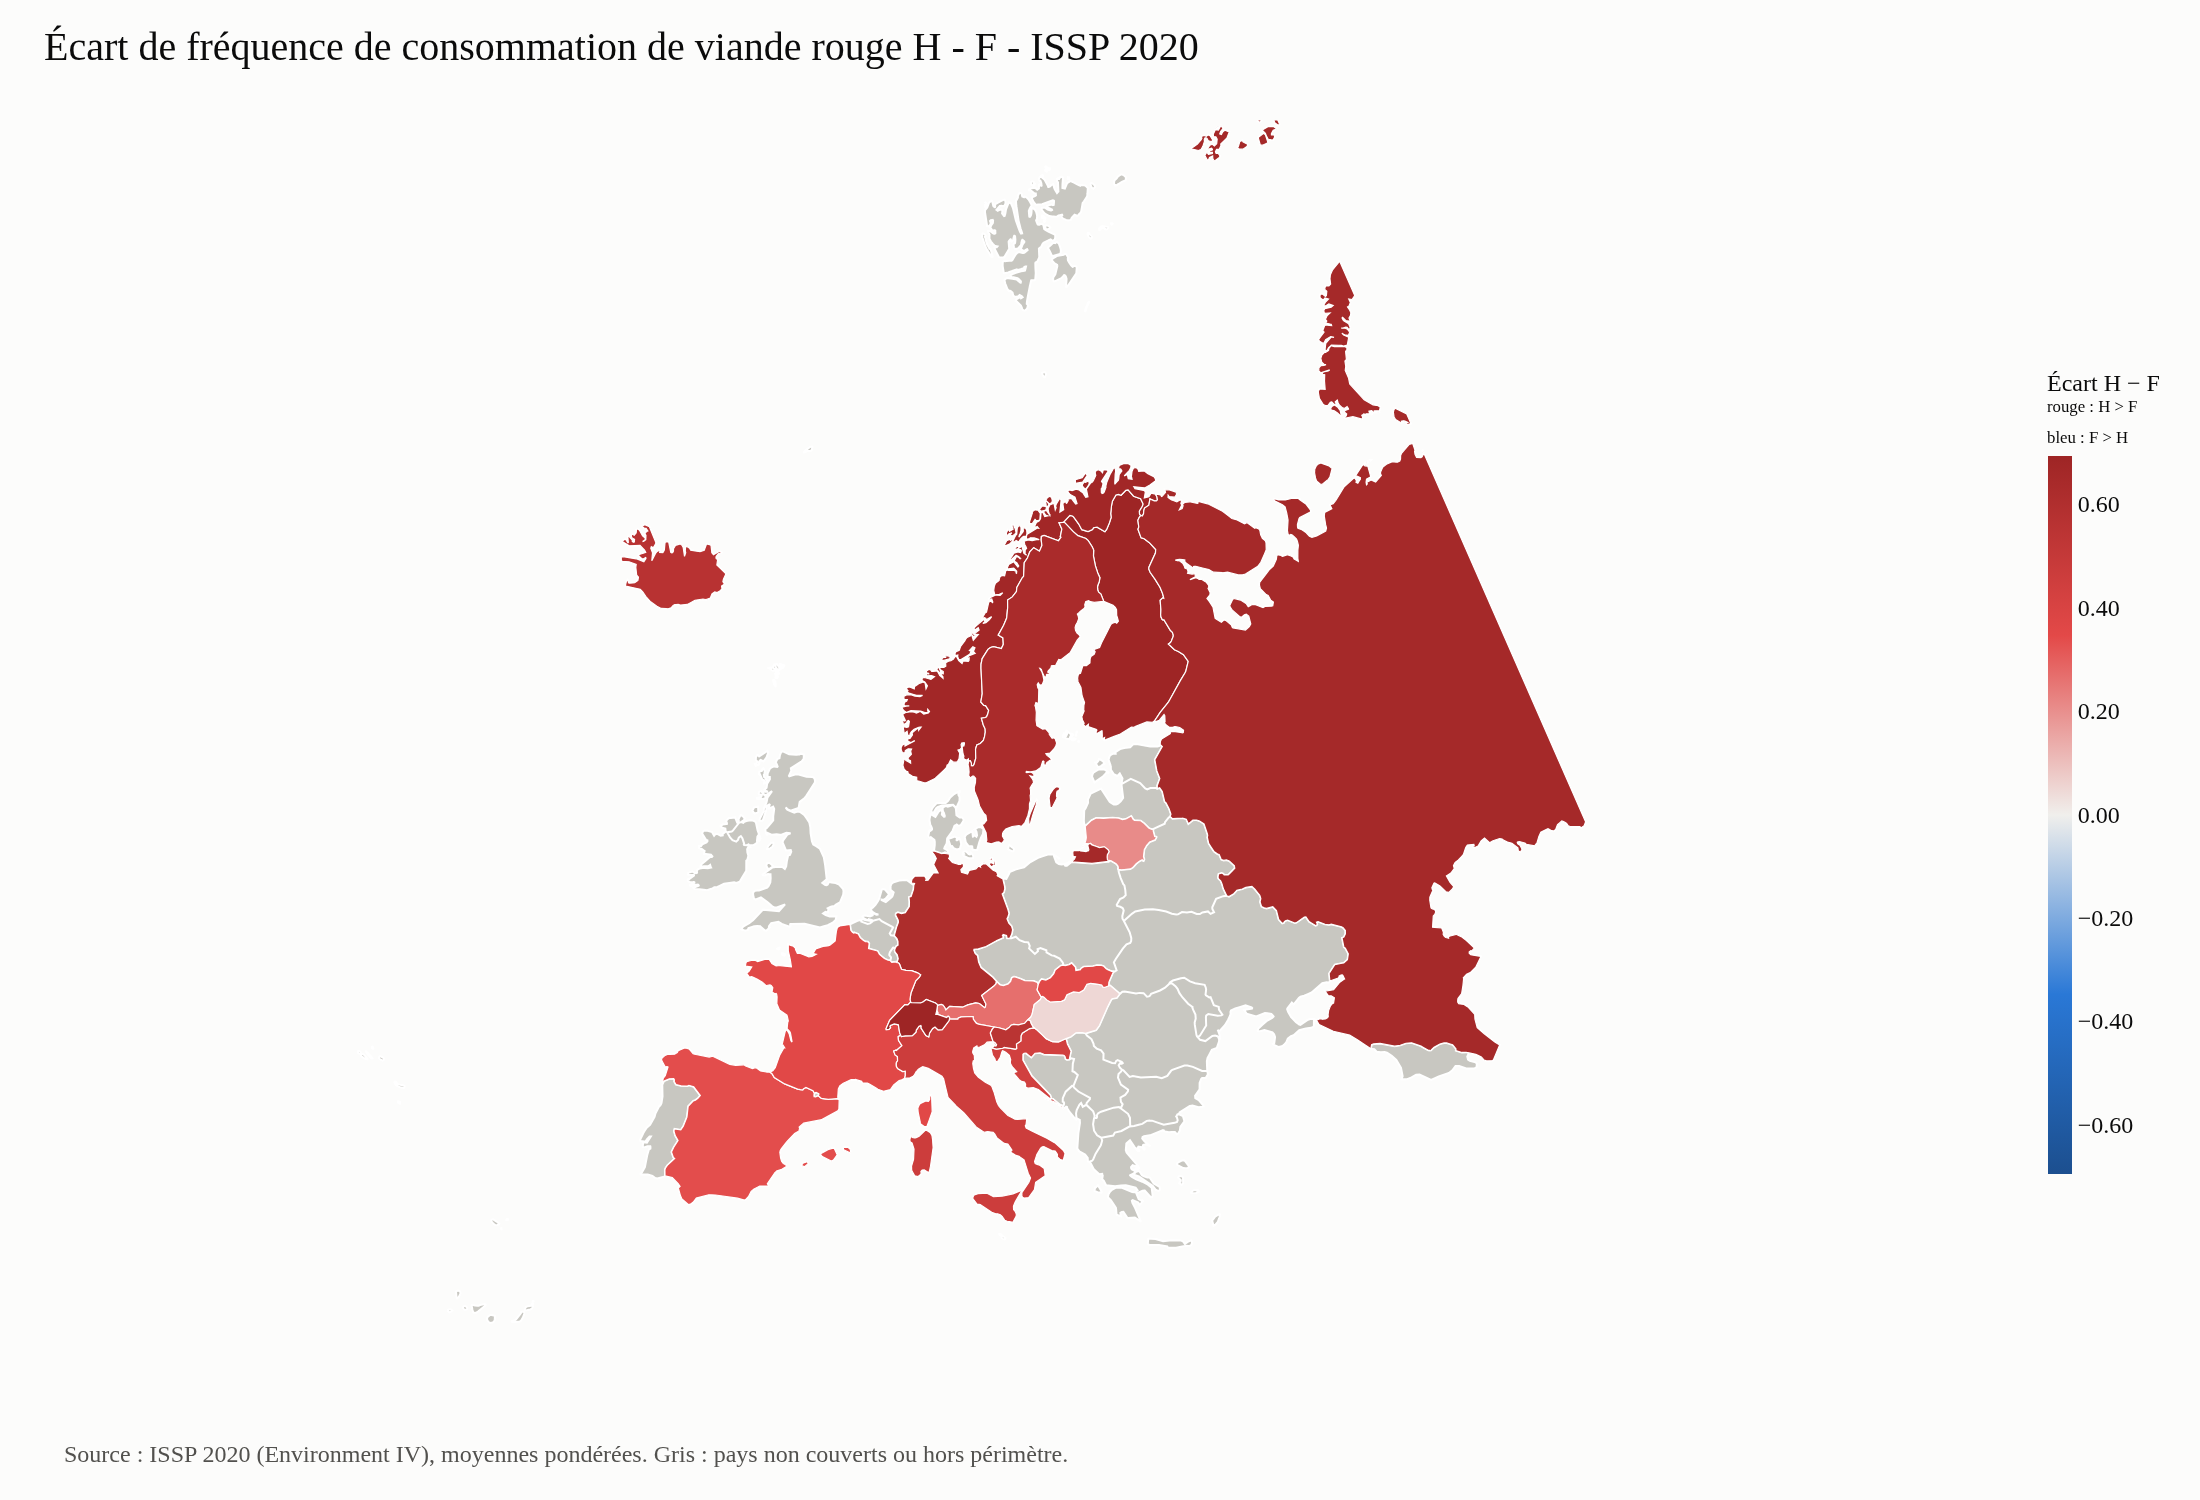

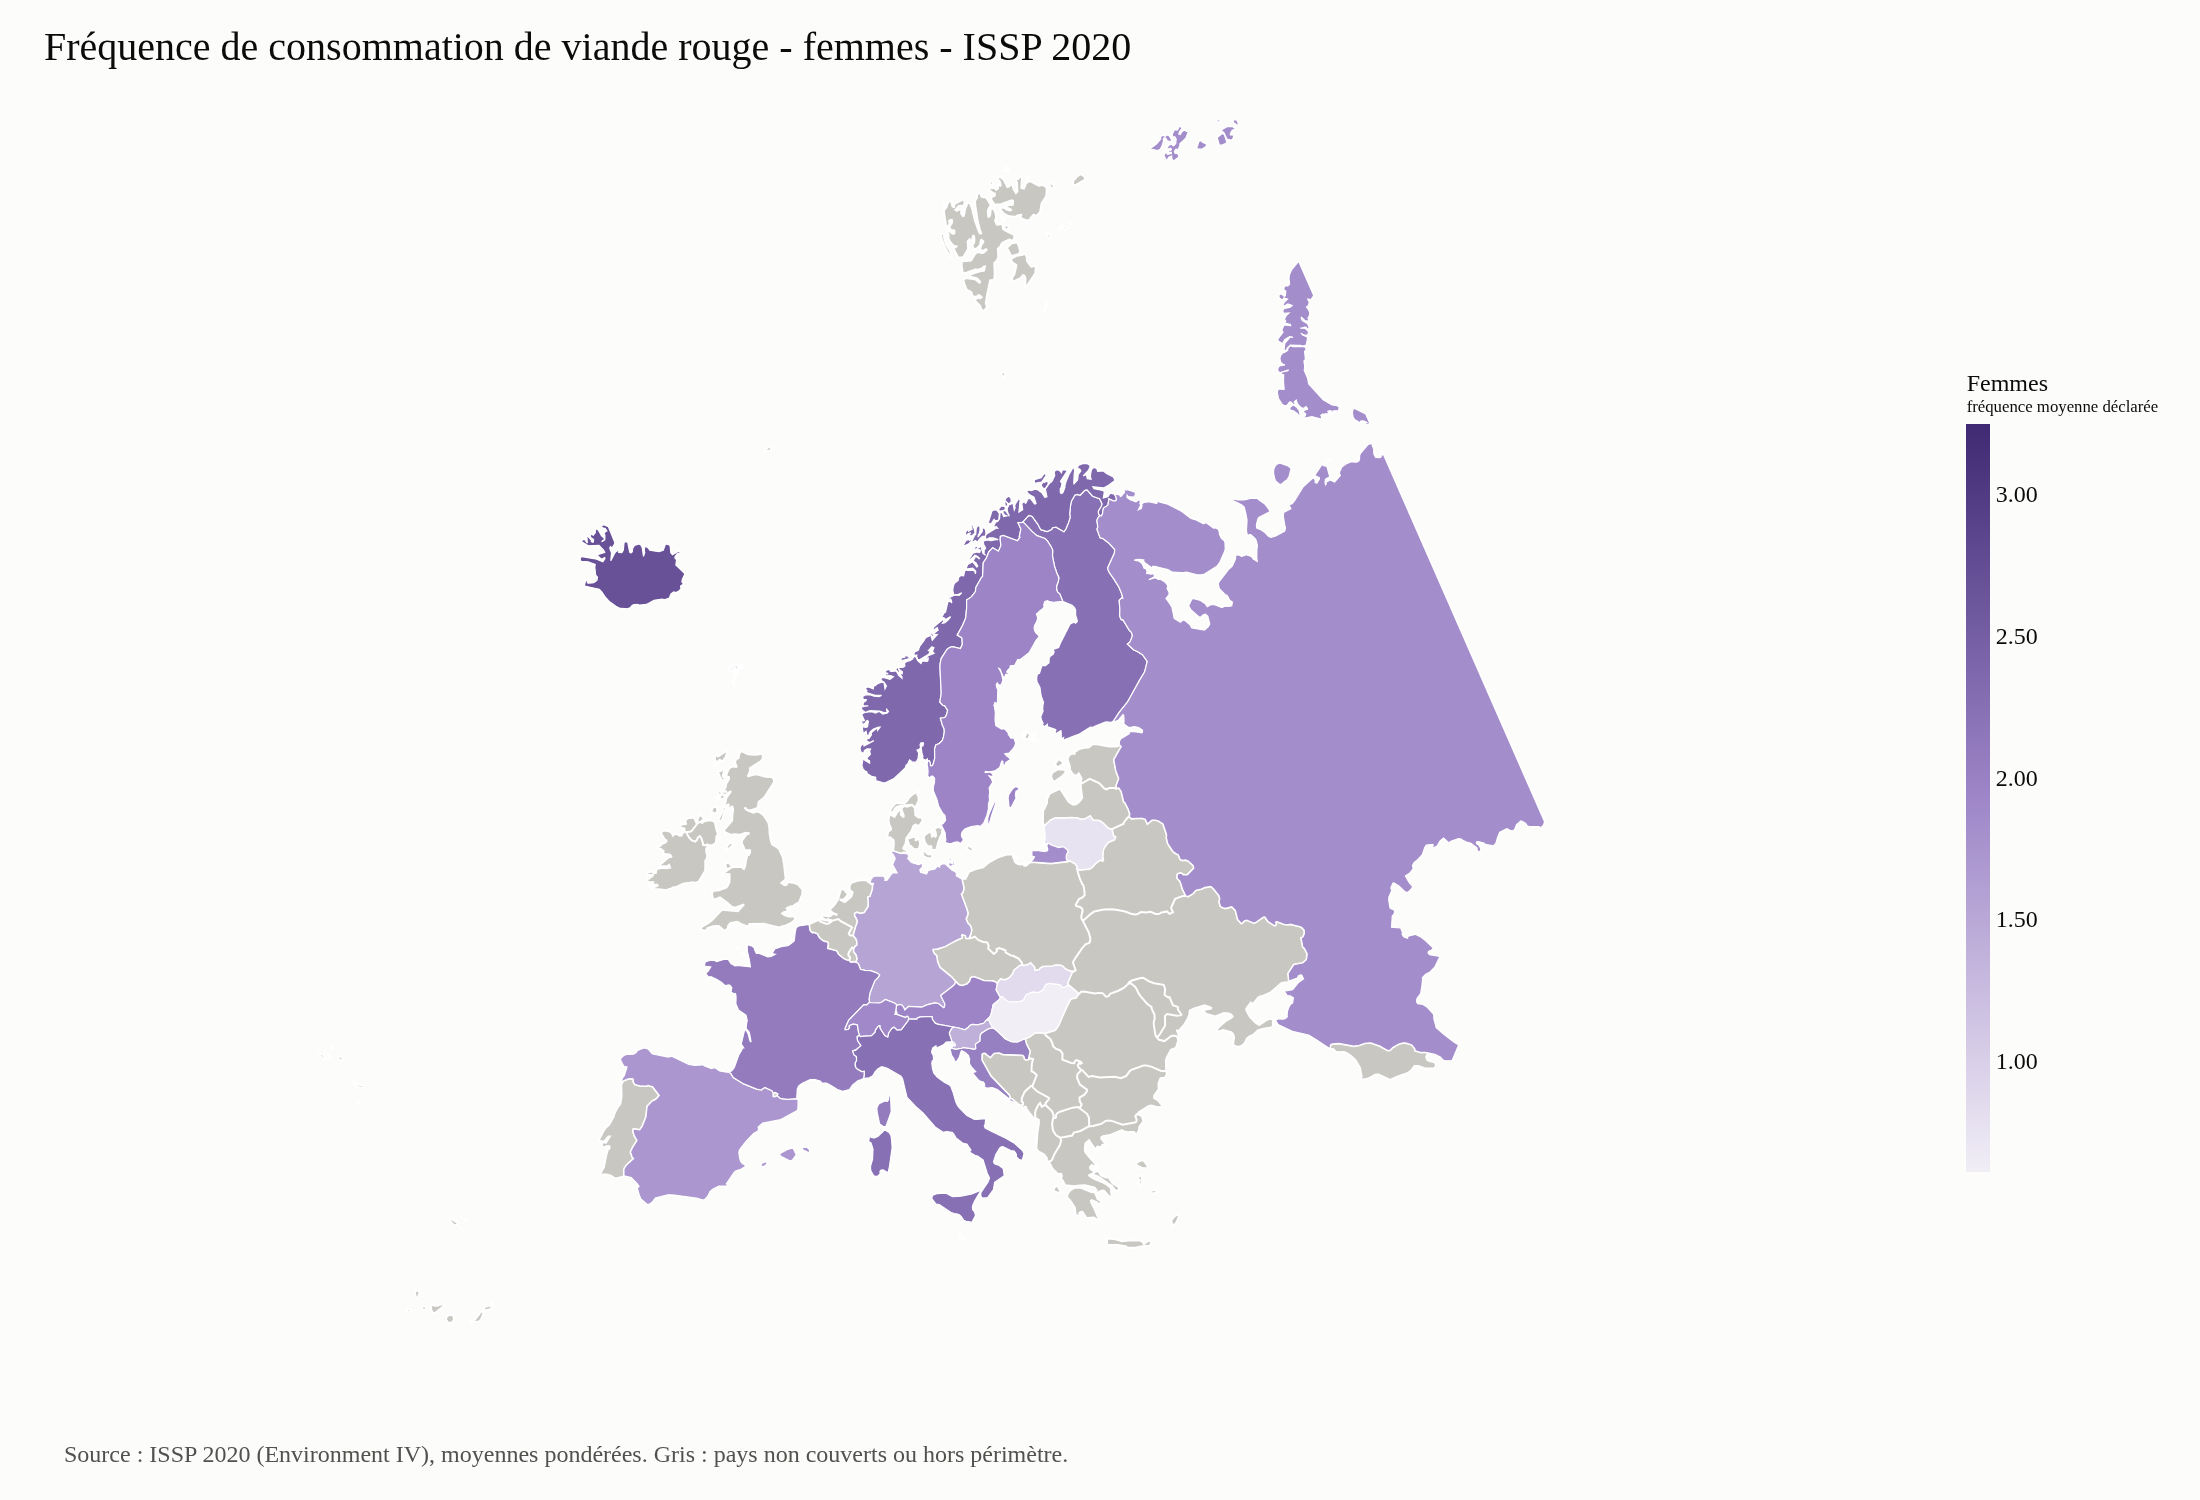

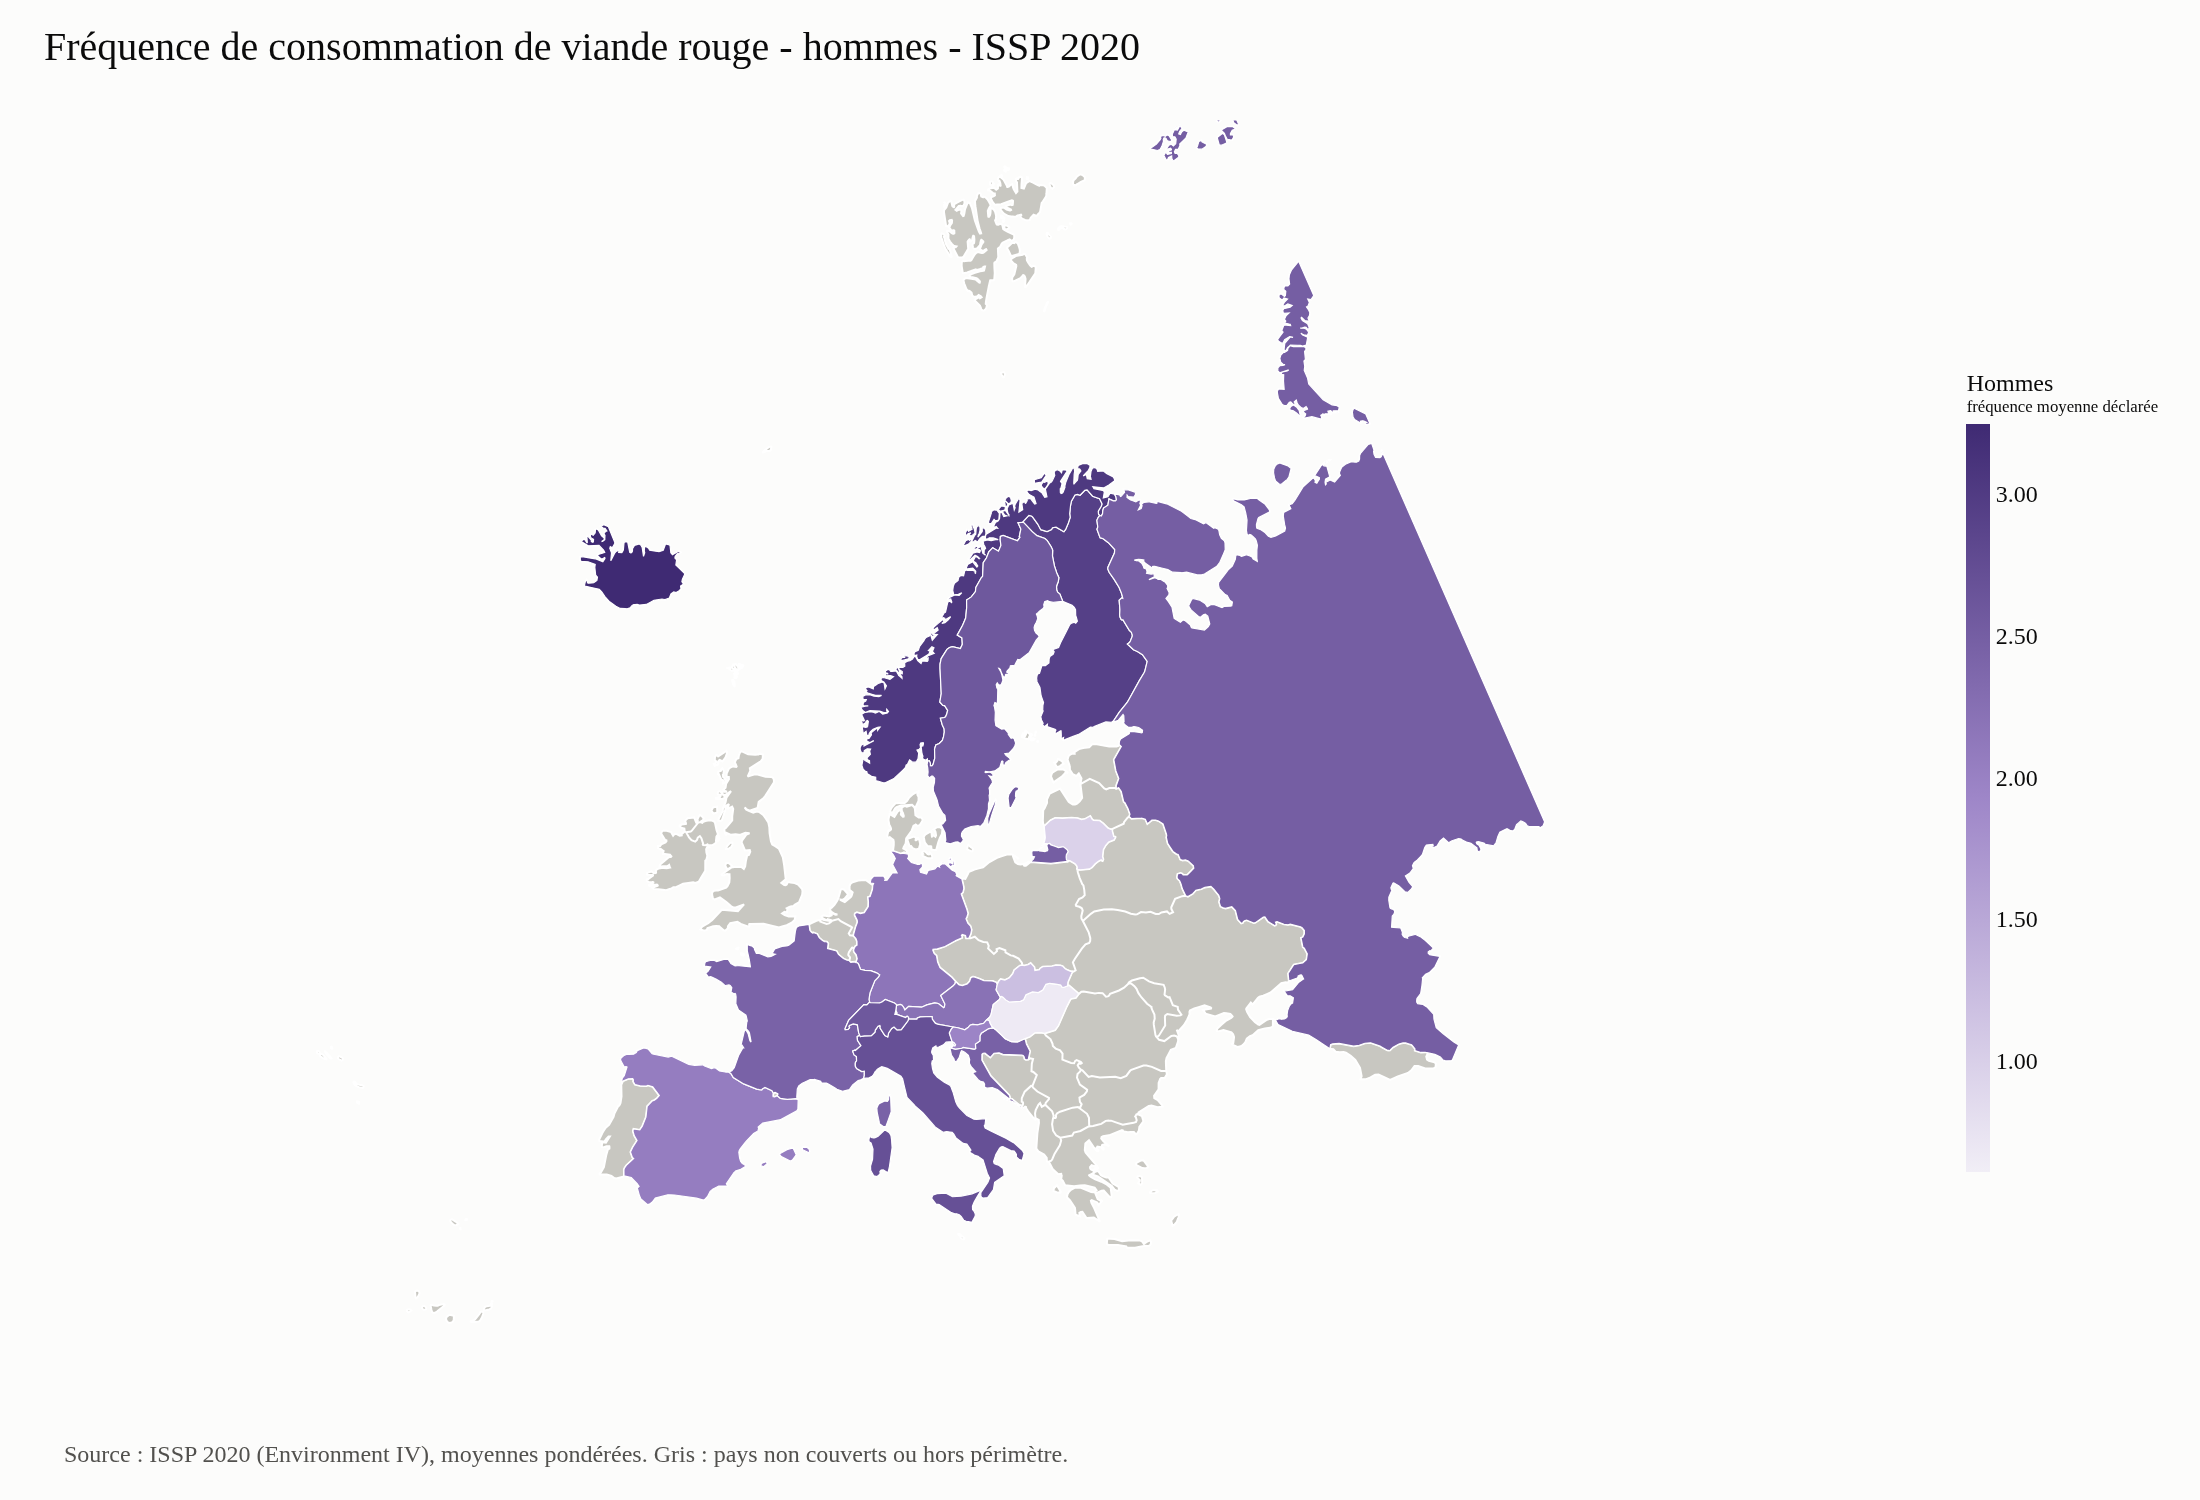

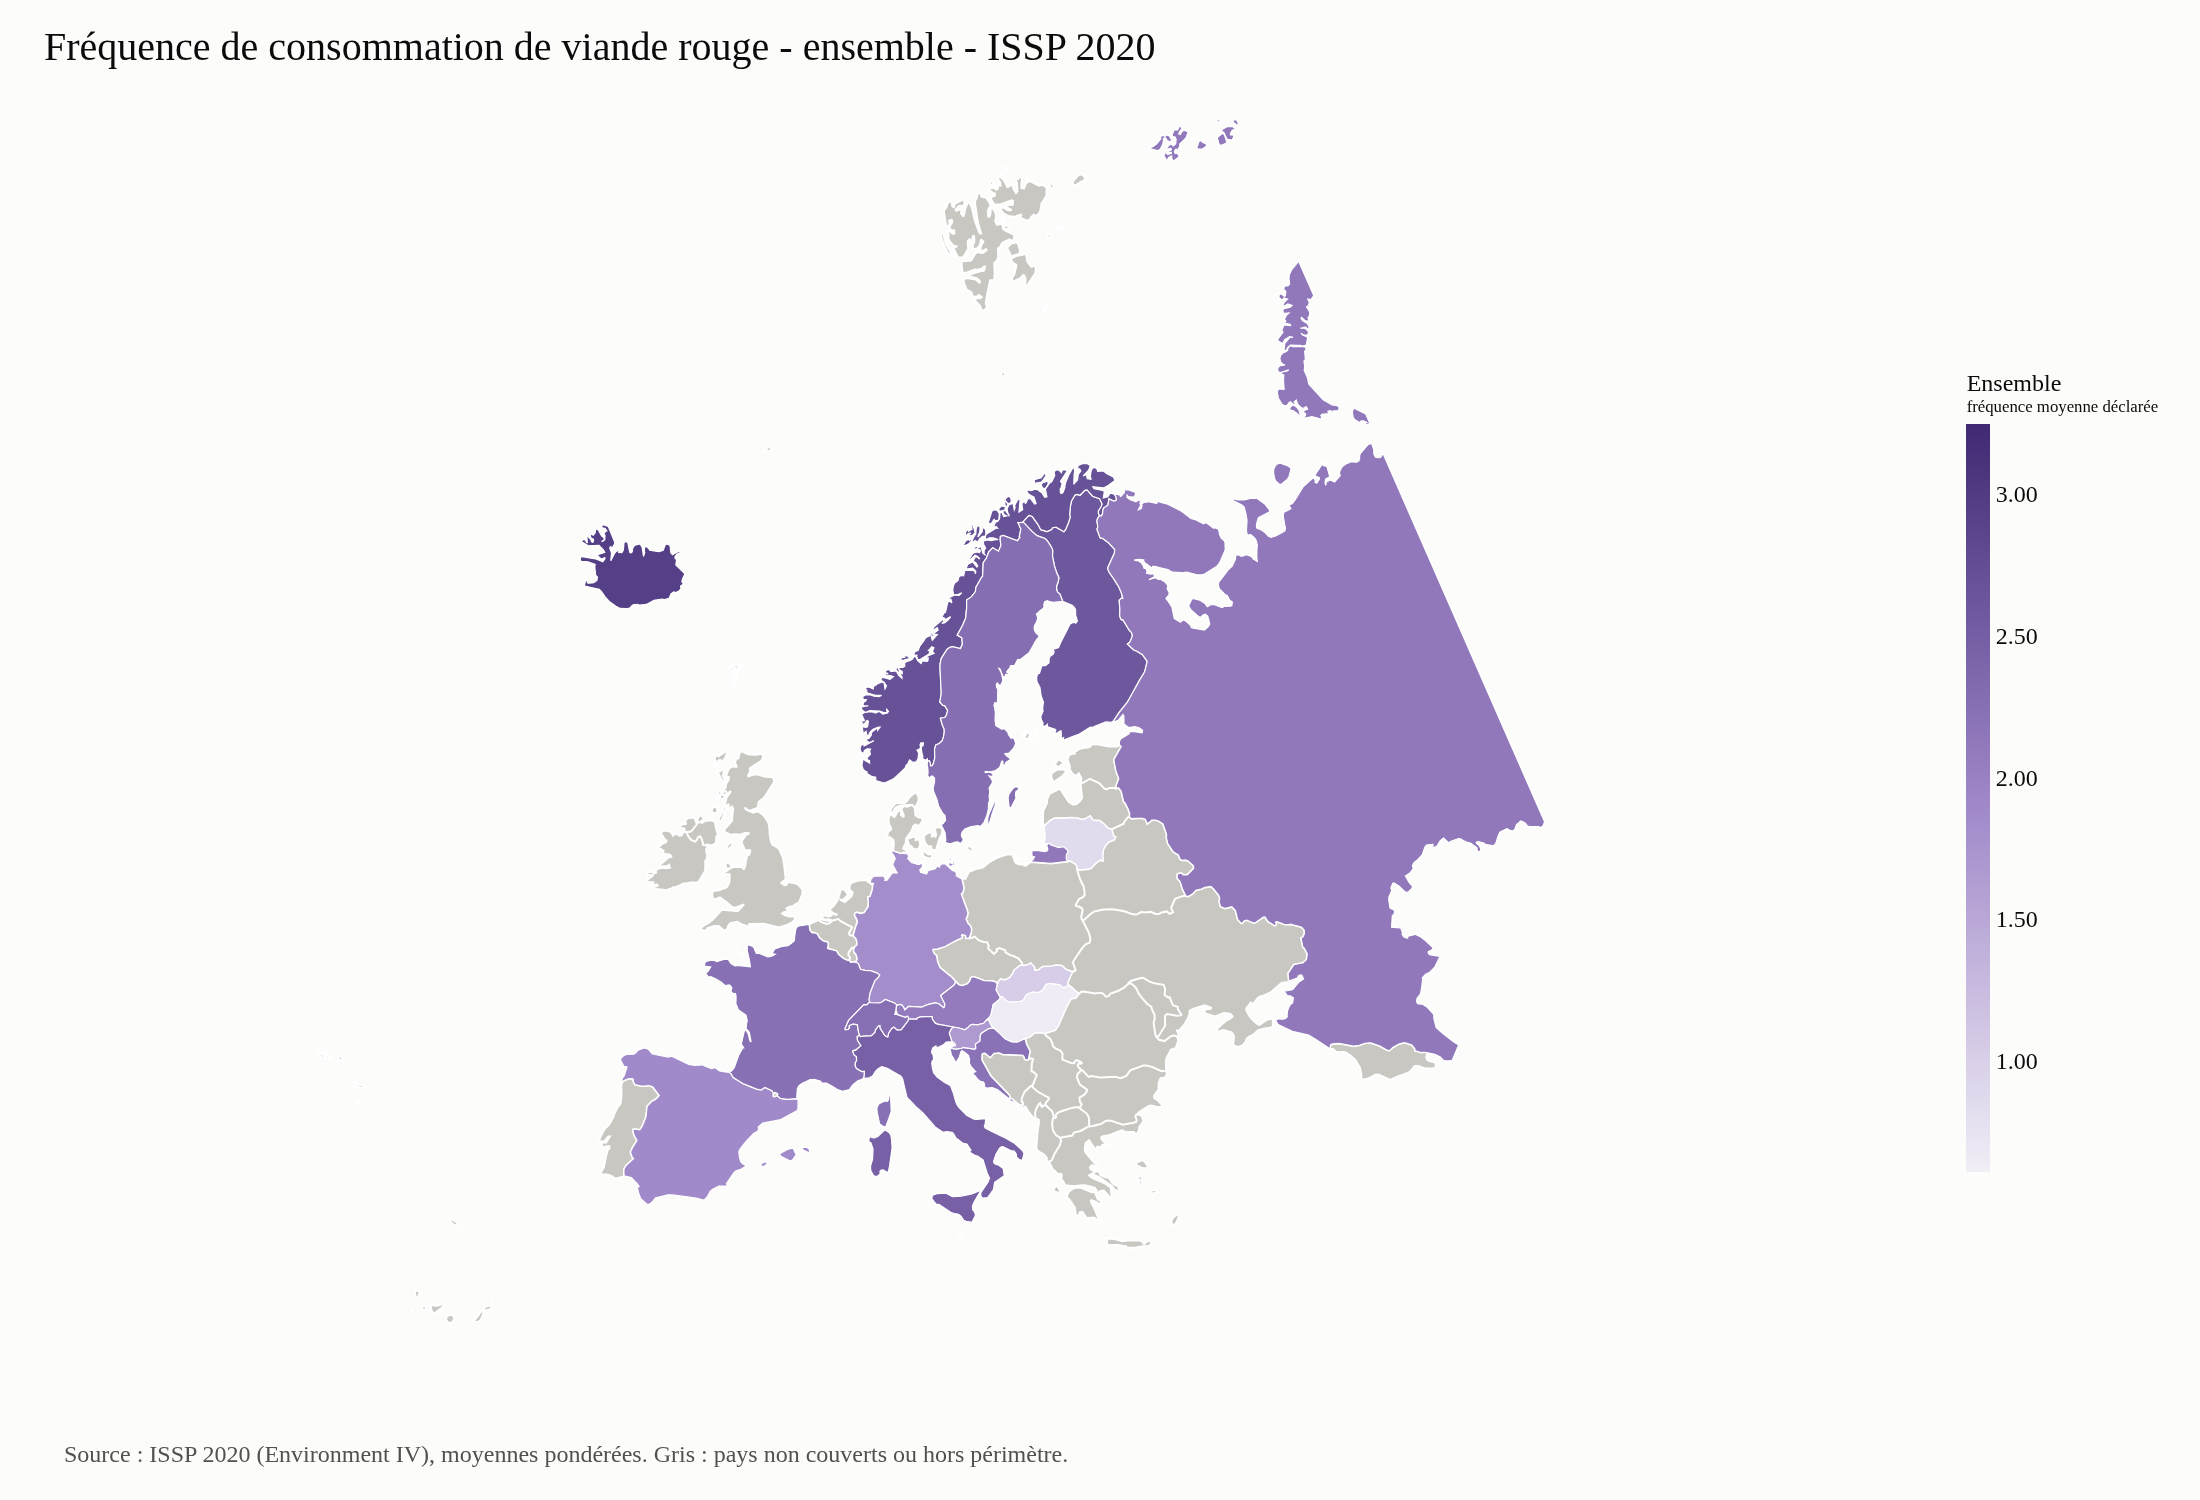

In [ ]:
afficher_sortie("carte_viande_ecart.png")
afficher_sortie("carte_viande_femmes.png")
afficher_sortie("carte_viande_hommes.png")
afficher_sortie("carte_viande_tous.png")

**Niveau de consommation** : On observe un contraste important entre pays du Nord et de l'Est. L'Islande, la Norvège et la Finlande sont les plus fortes consommatrices, avec la Suisse, l'Italie et la France. La Hongrie, la Lituanie et la Slovaquie sont nettement en dessous. Les pays nordiques tirent donc bien la moyenne vers le haut, sauf la Suède, qui est dans la moyenne.

**Prise en compte du genre** : Les cartes « hommes » et « femmes » classent les pays presque dans le même ordre, les hommes étant simplement un cran plus haut partout. Il semble donc que la culture alimentaire nationale pèse plus que le sexe dans les différences entre pays.

**Écart hommes−femmes** : Comme établi par les statistiques descriptives, il est positif partout. Toutefois, on voit ici qu'il est plus fort en Suisse, dans les pays nordiques, en Russie, en Allemagne et en Italie, et plus faible en Hongrie (quasi nul) et en Lituanie.


### Masculinité ressentie 


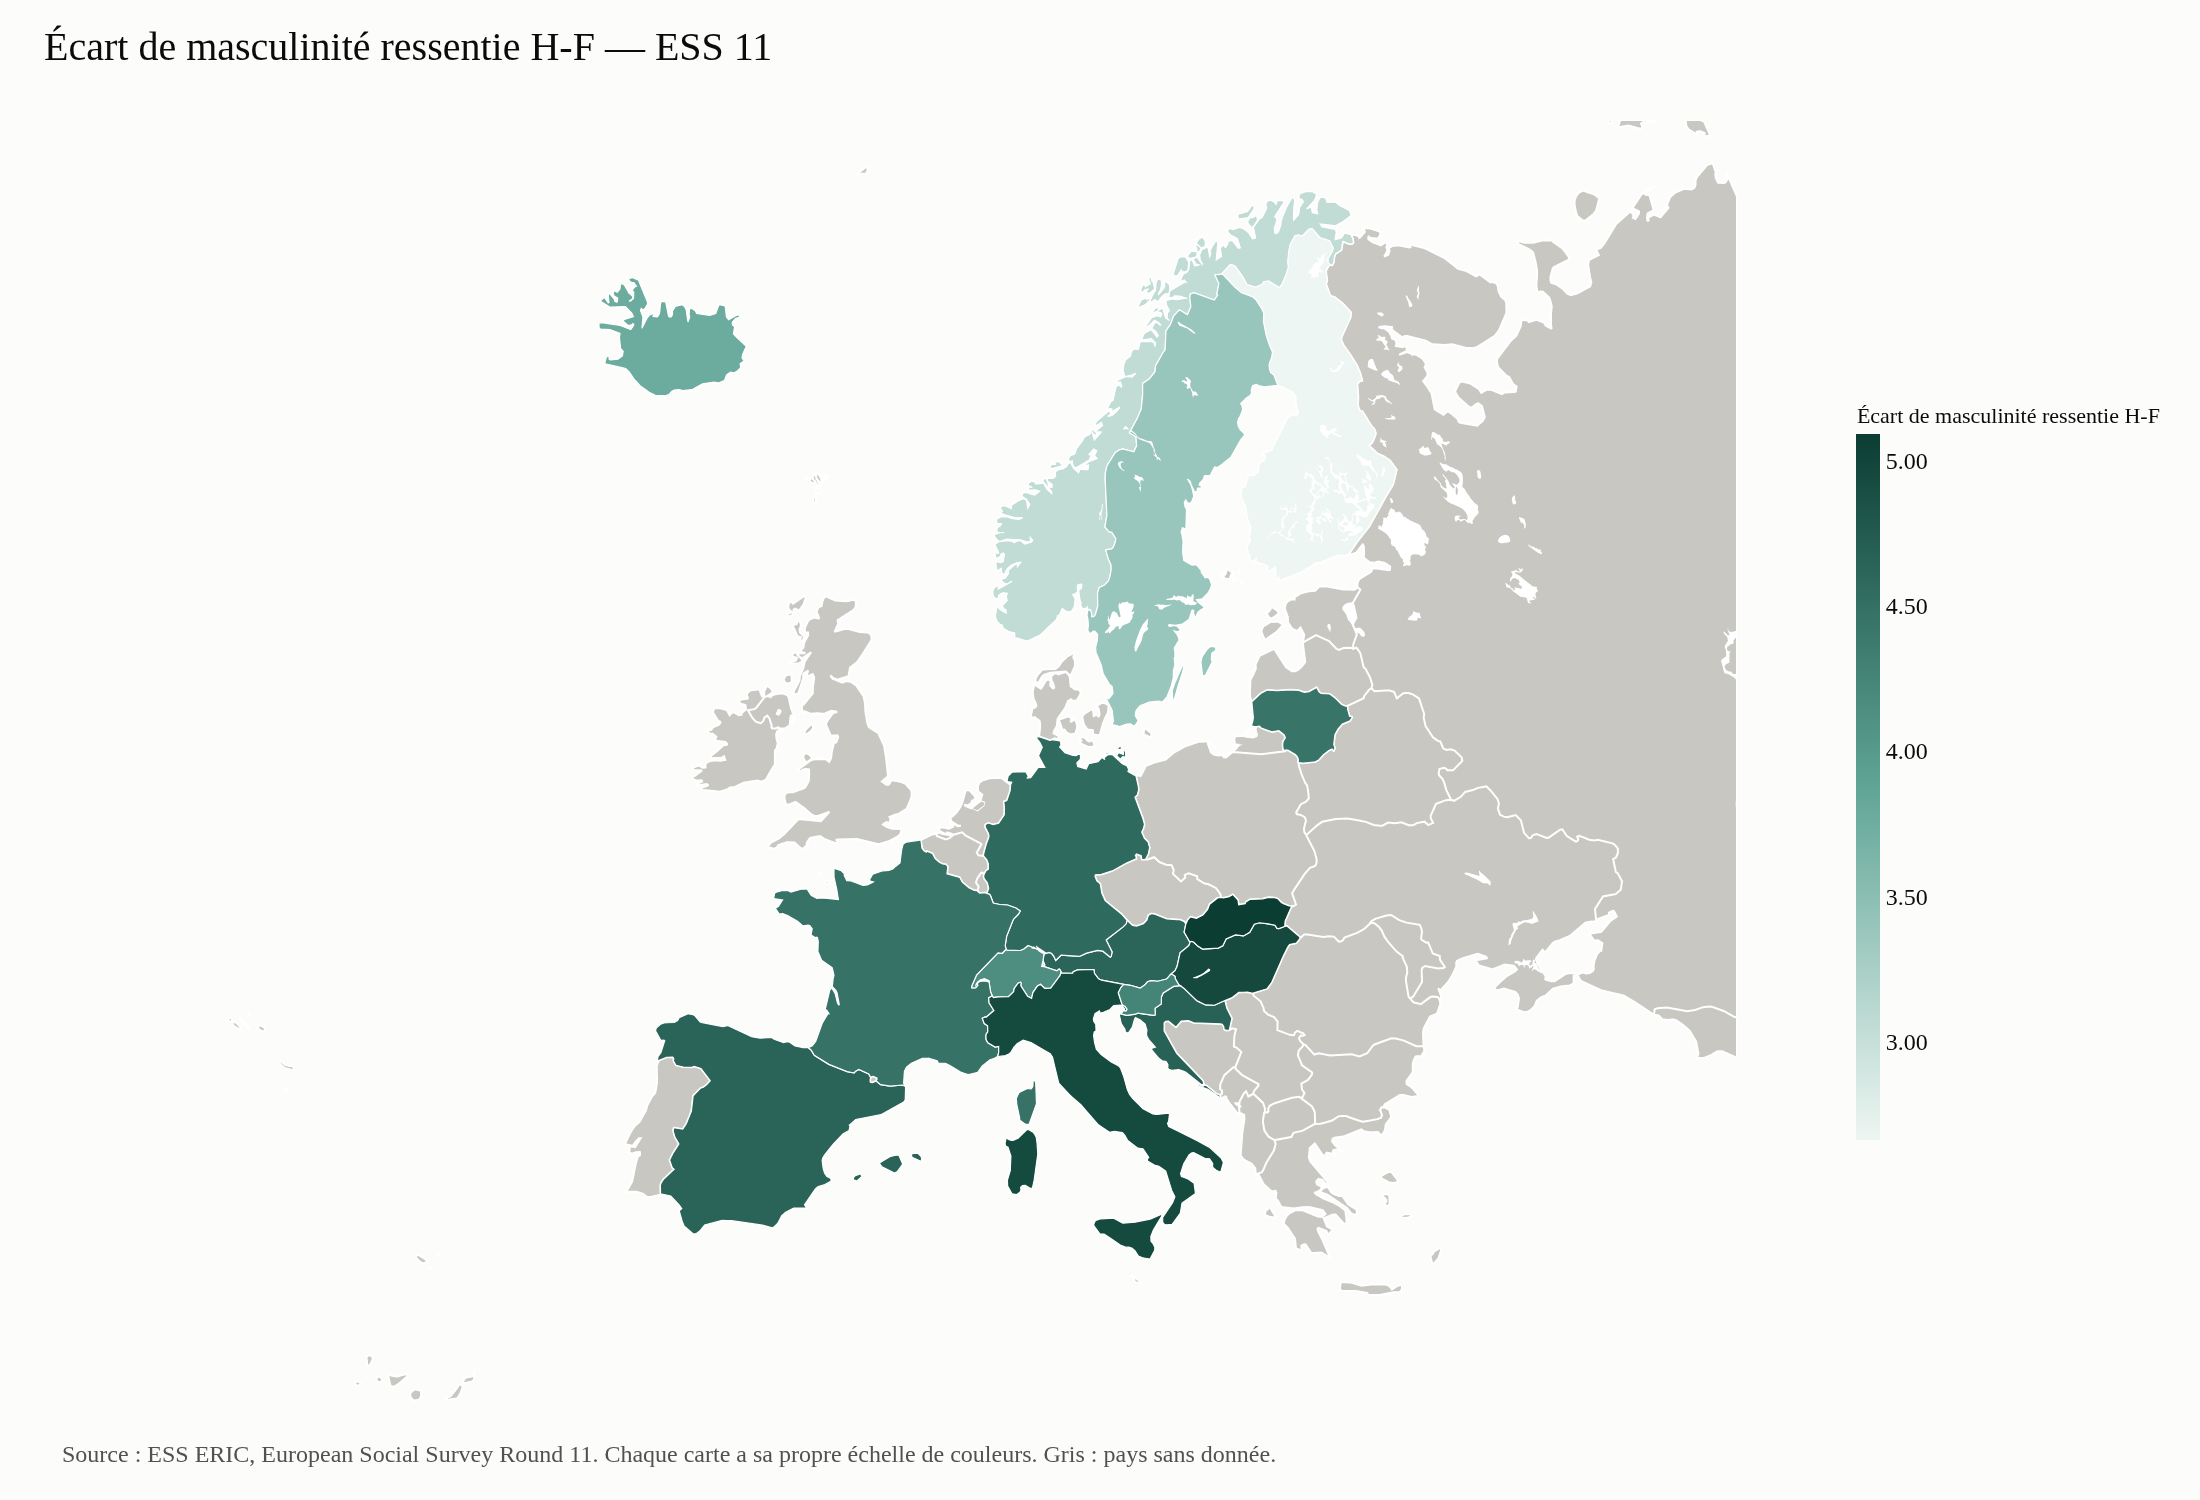

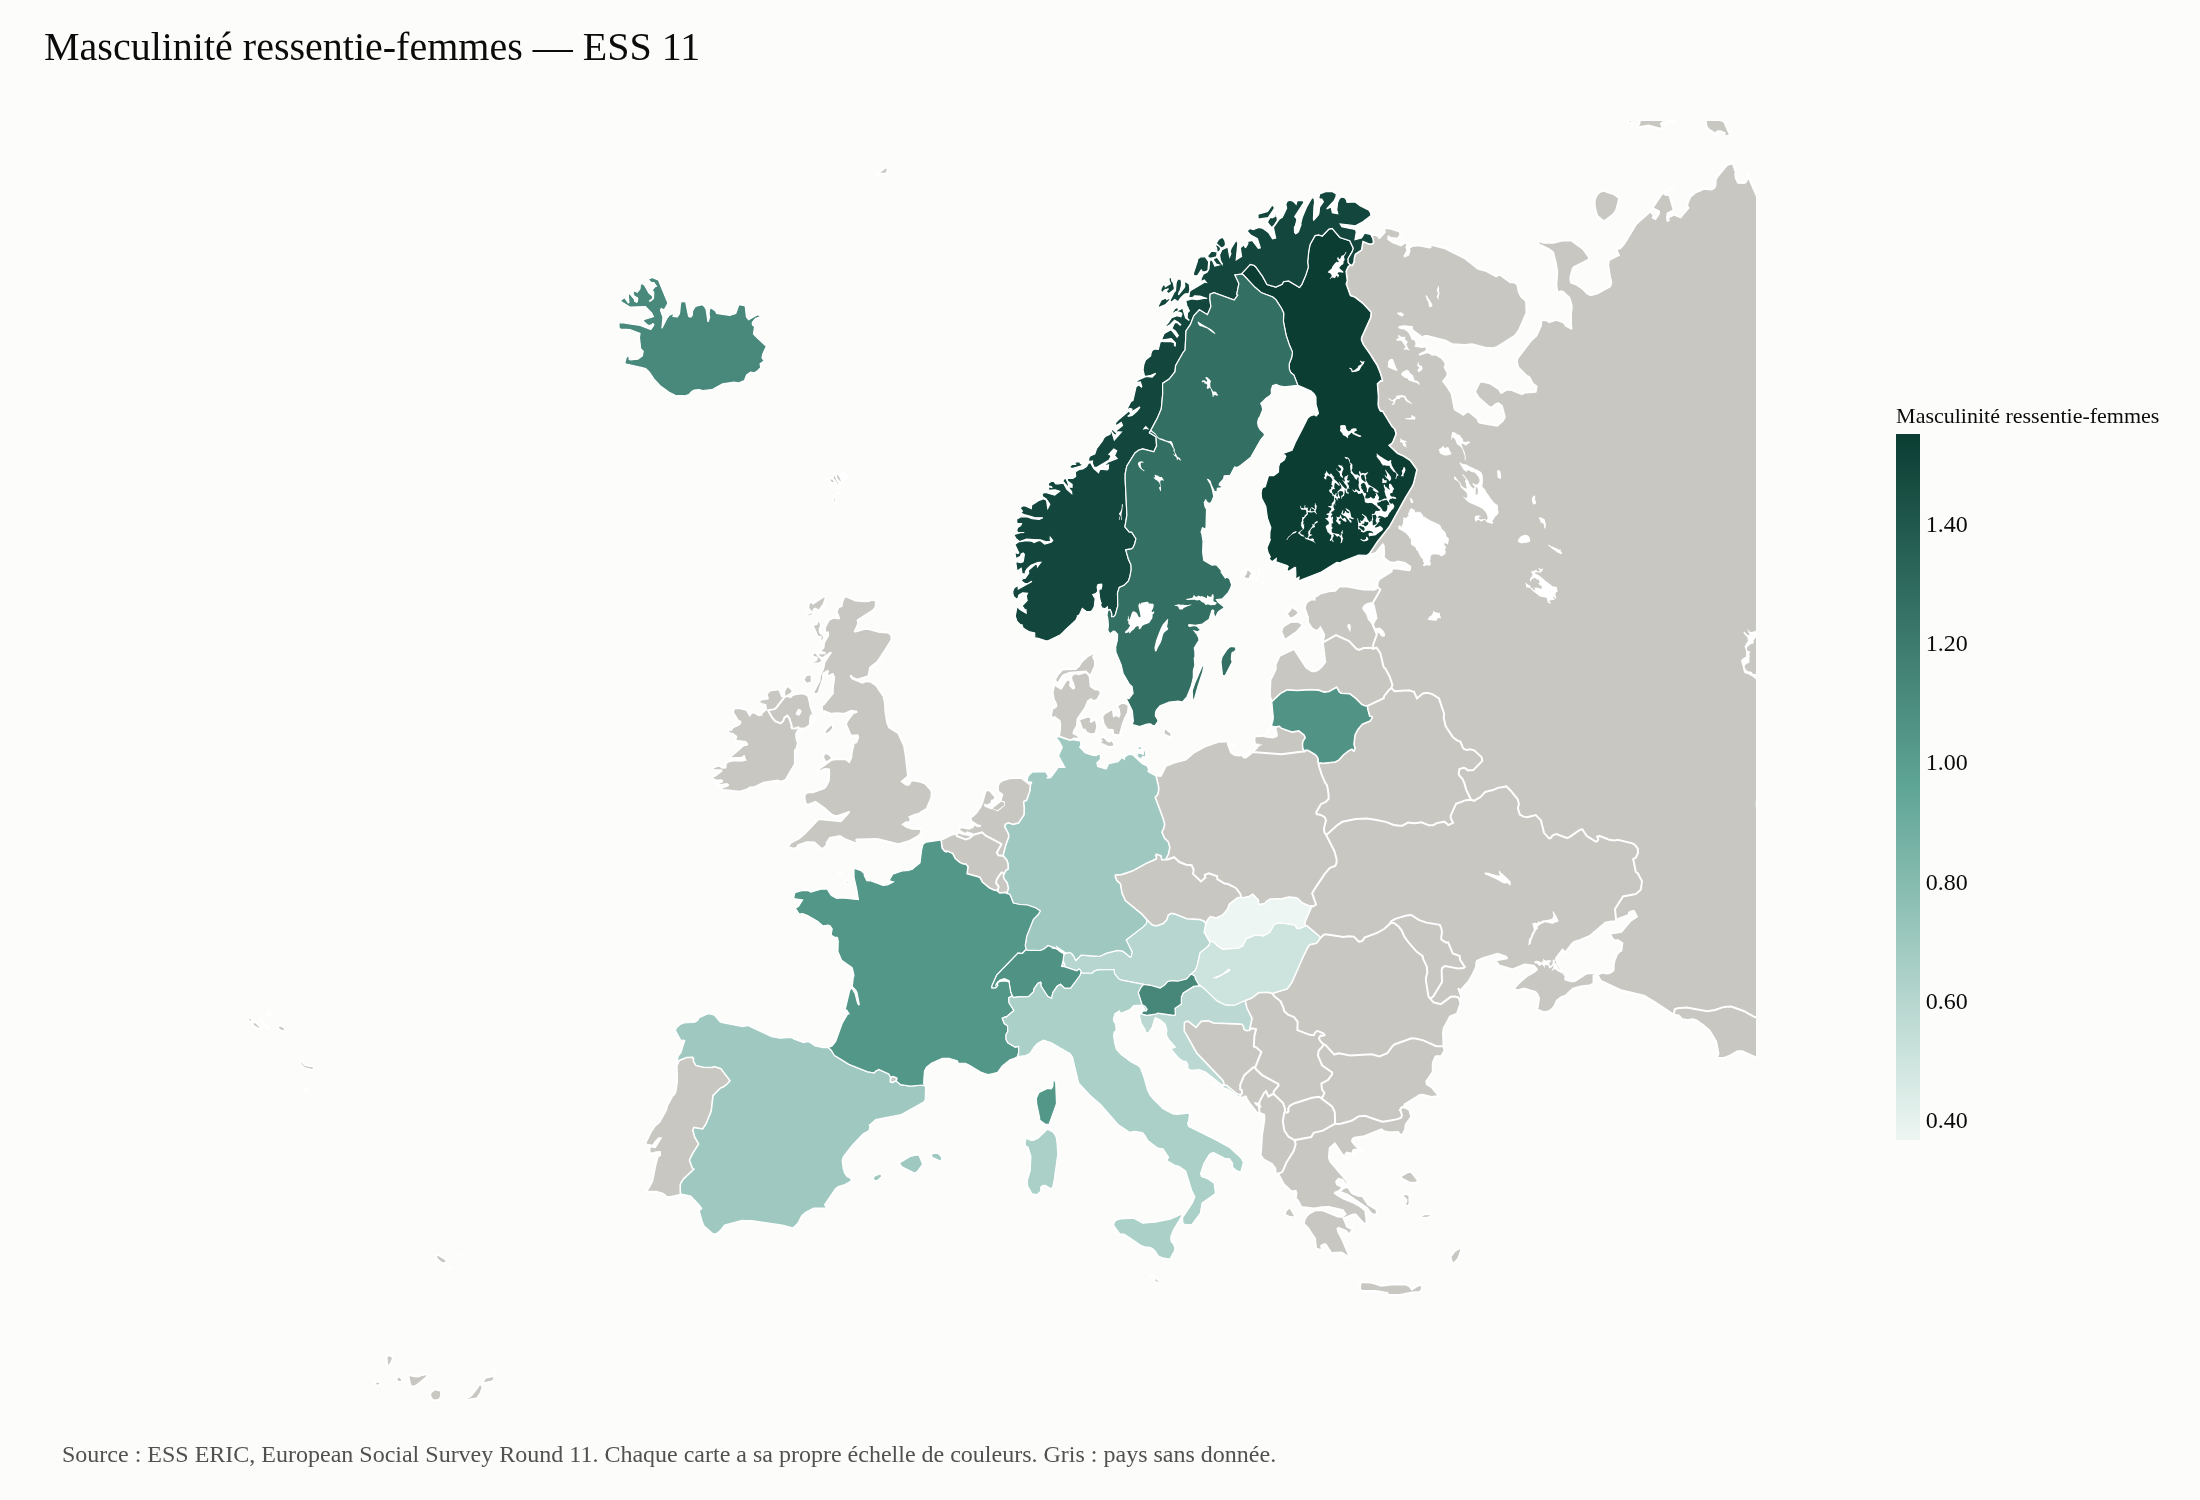

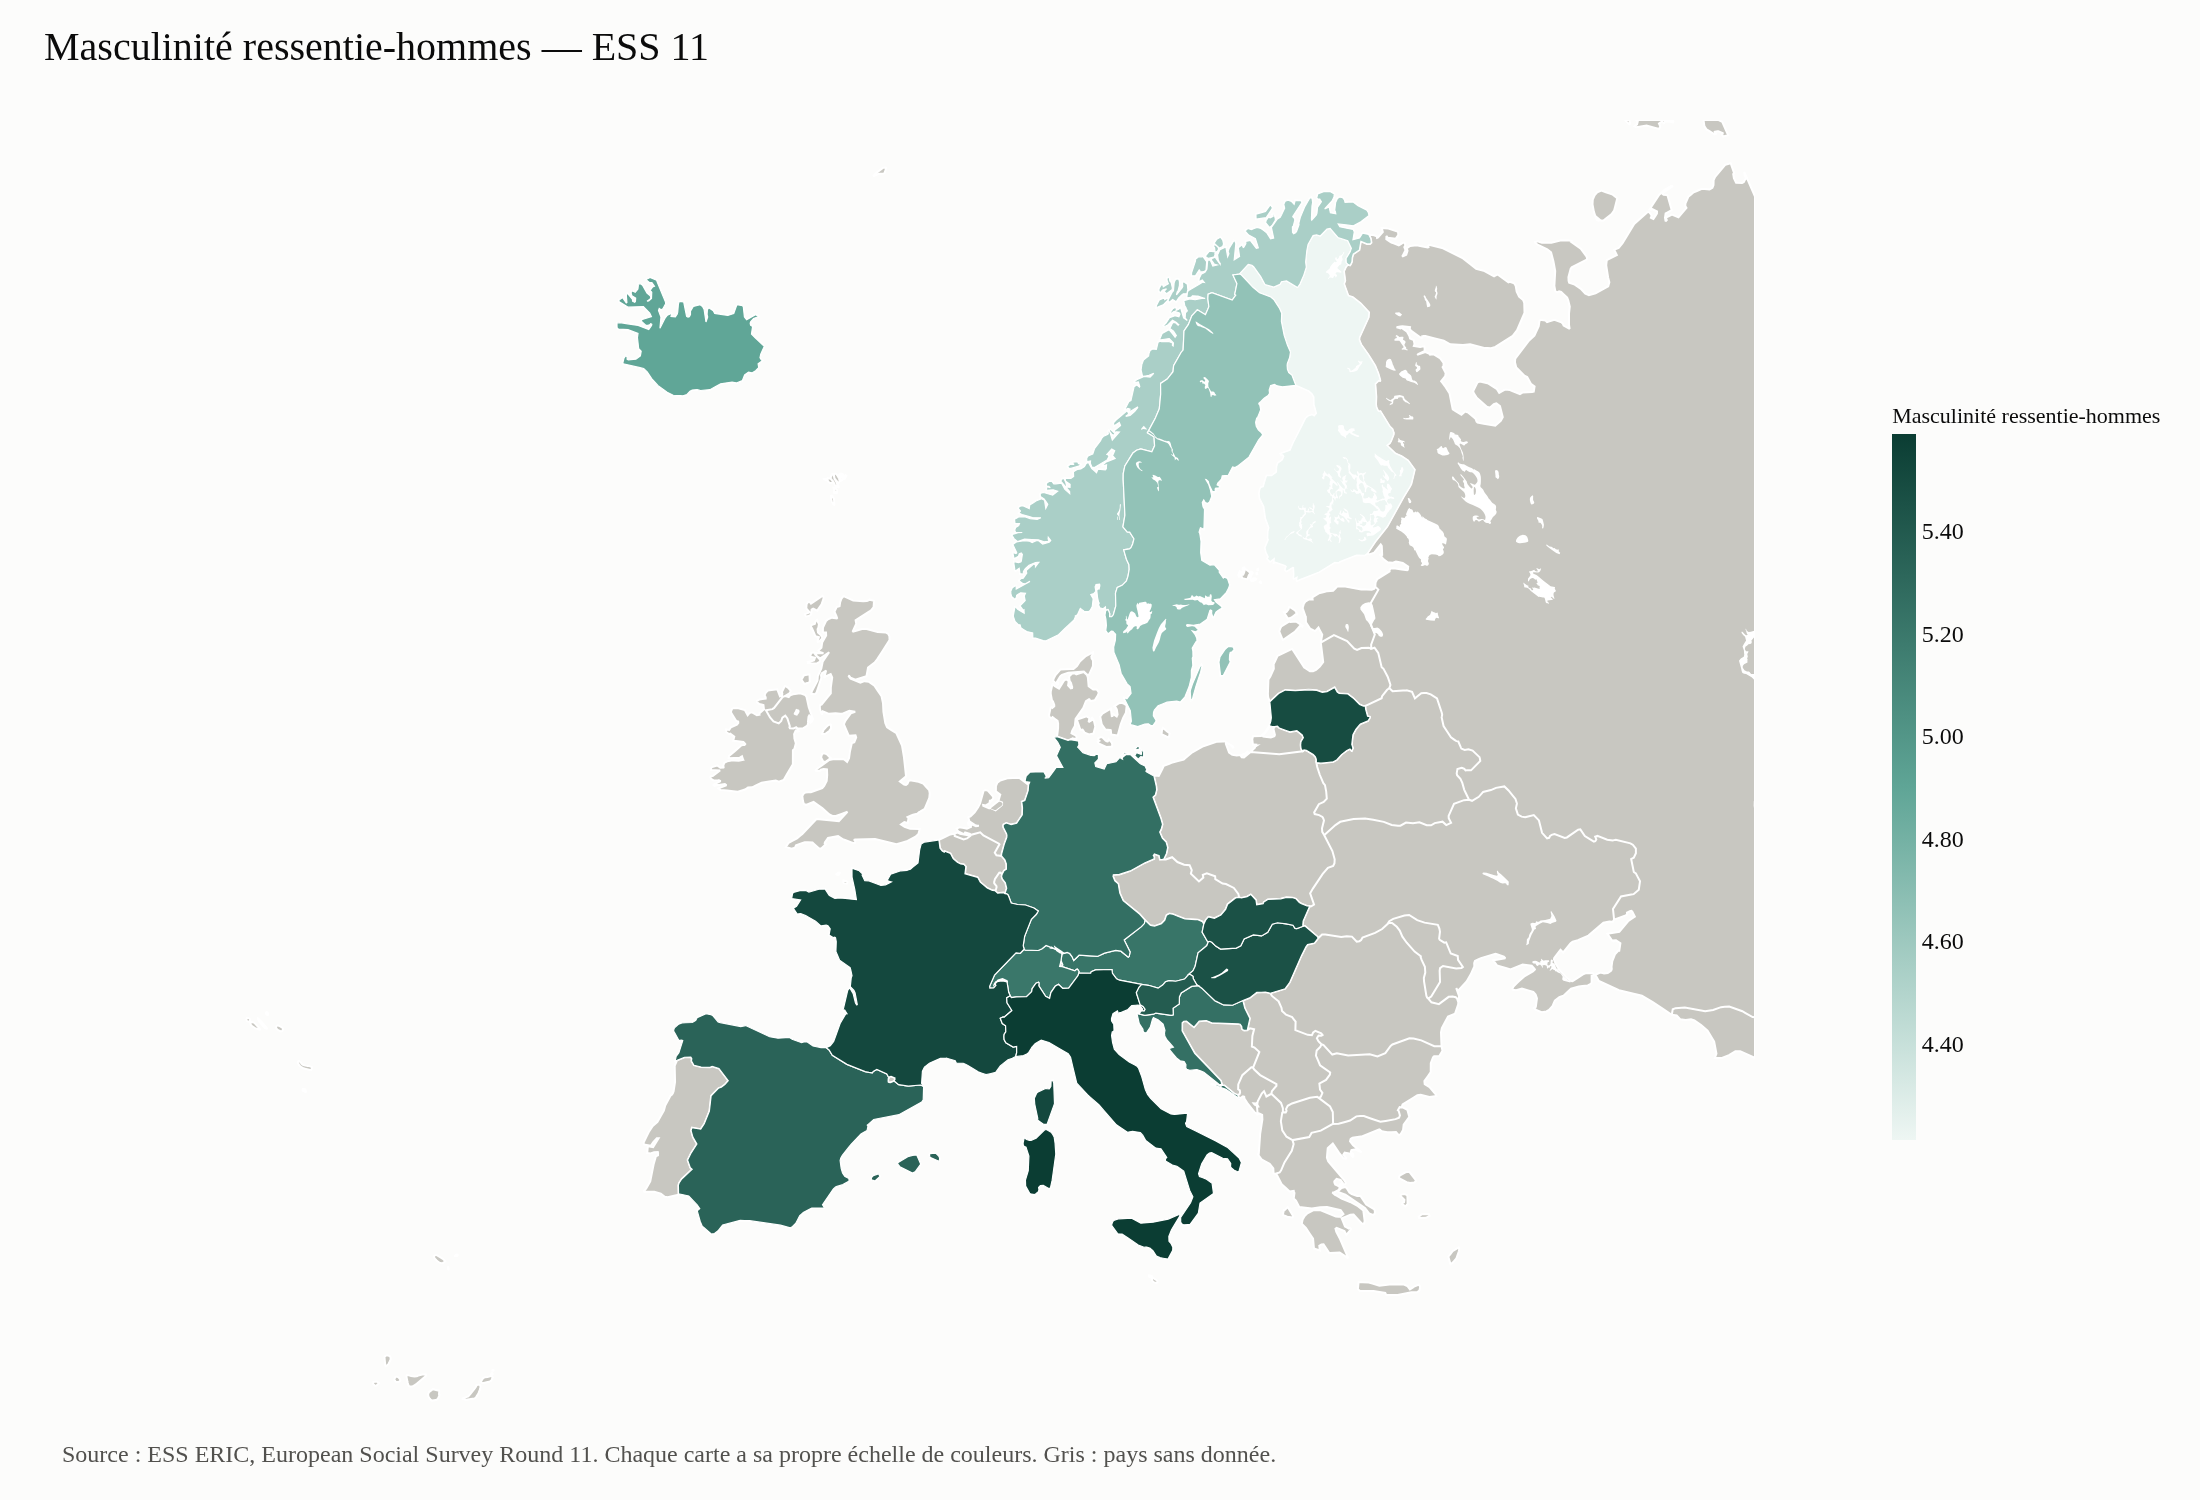

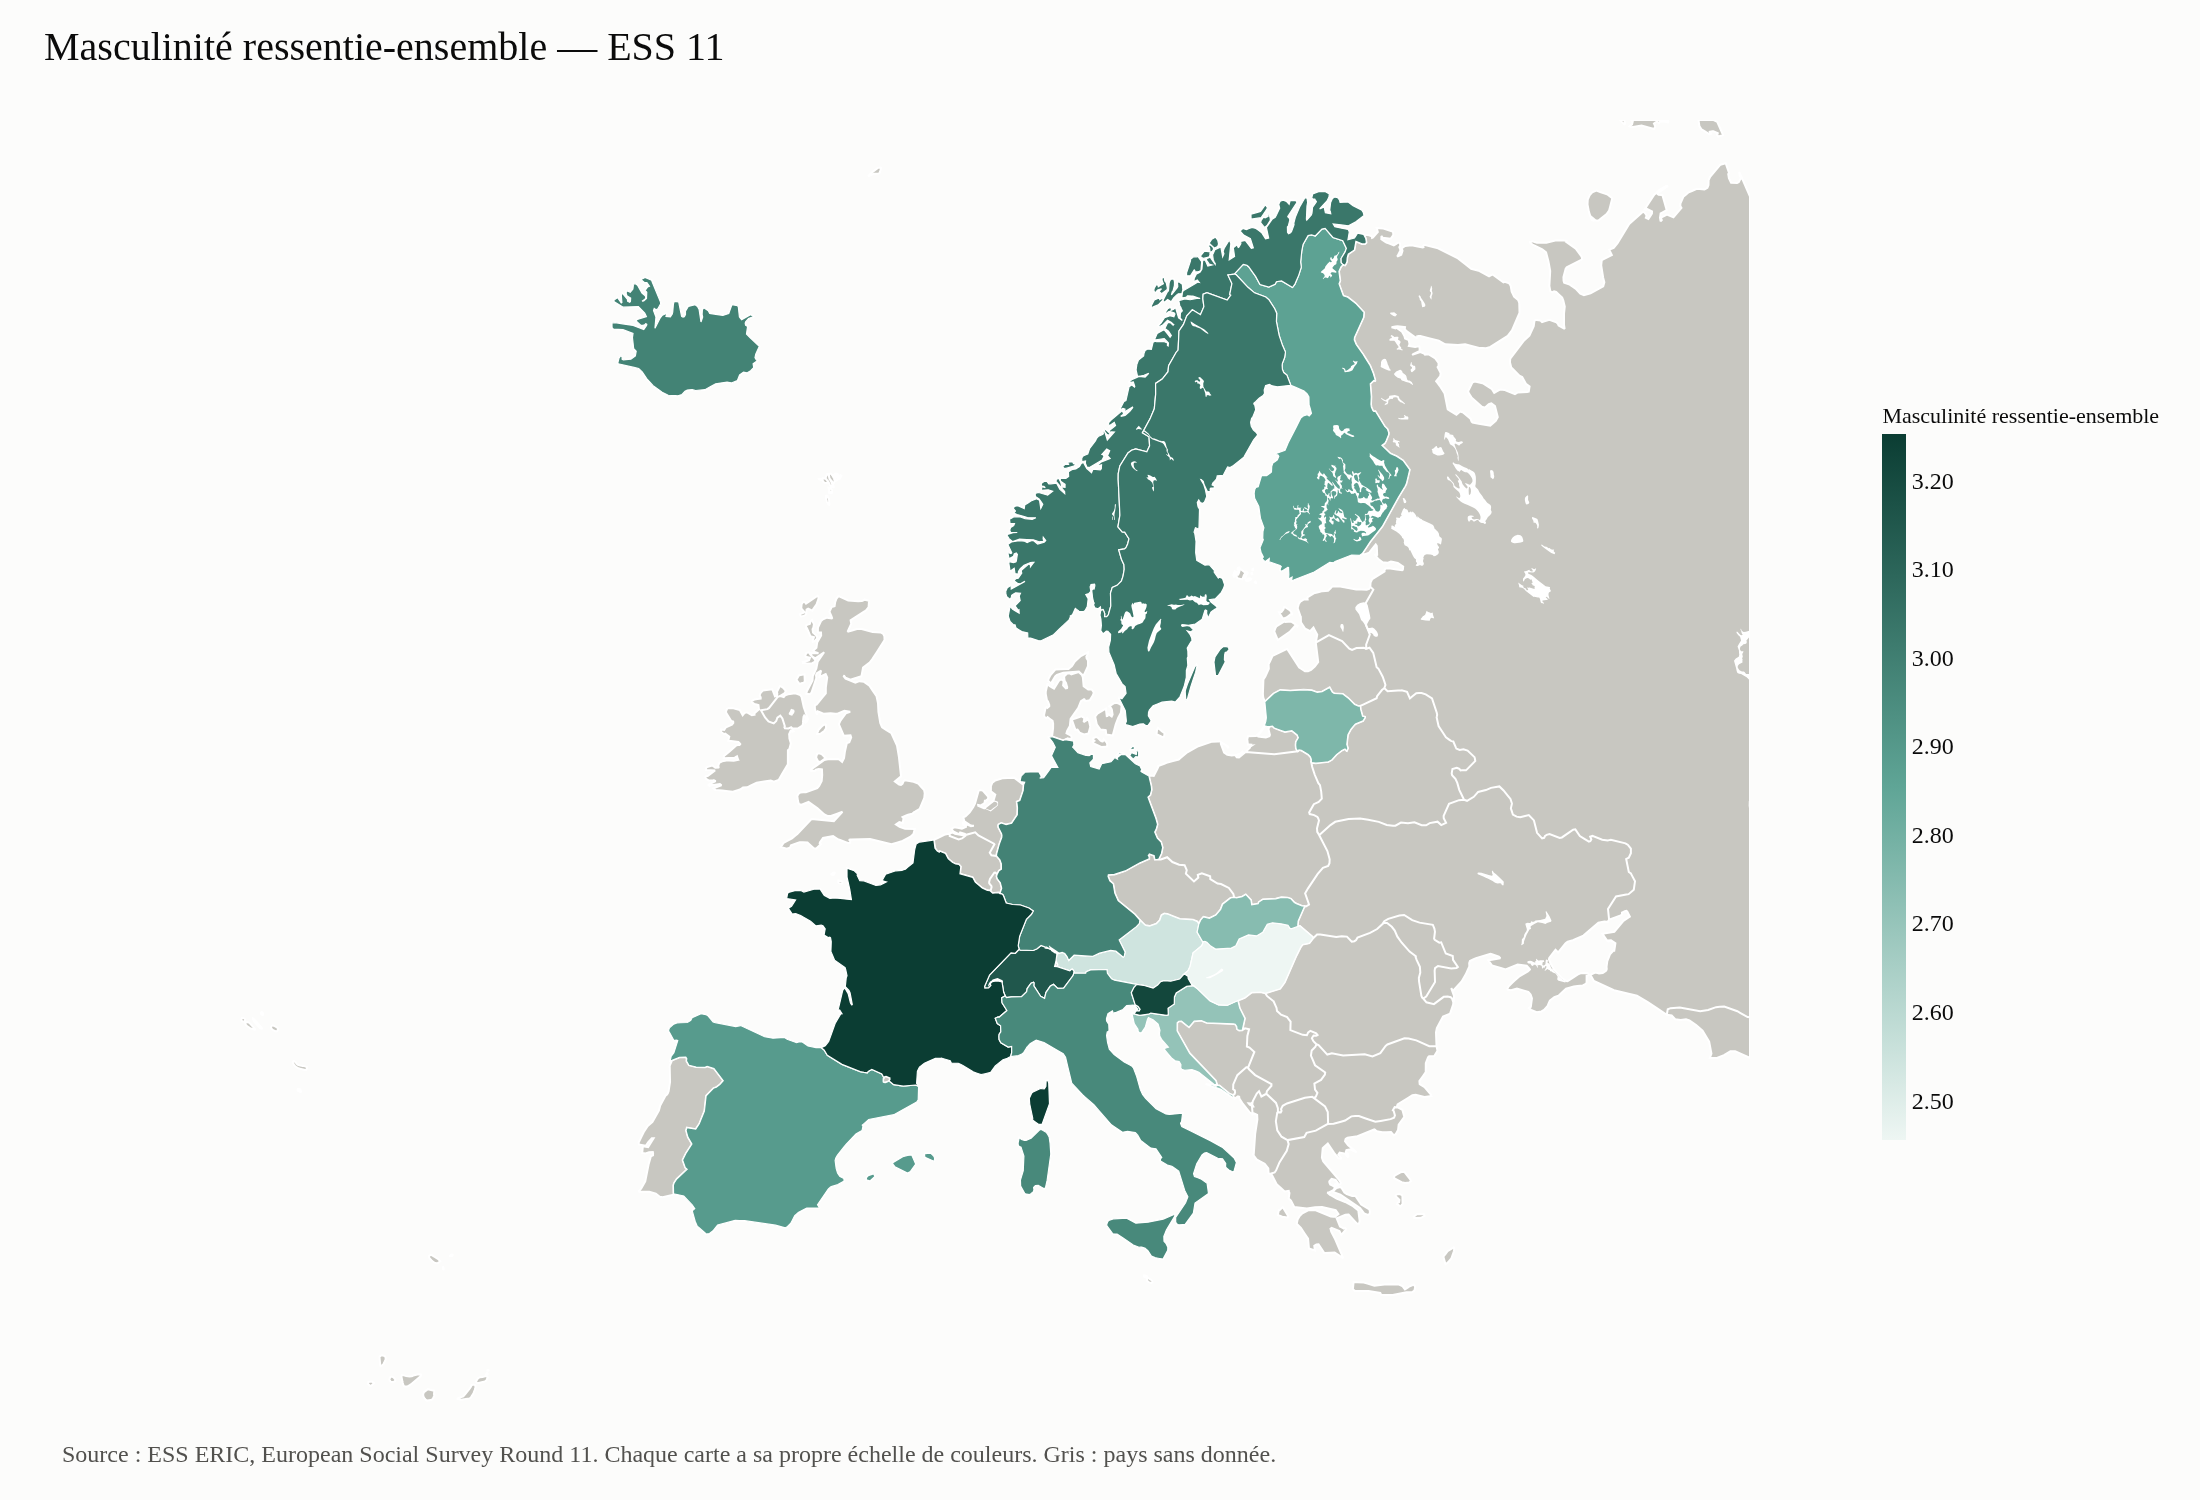

In [ ]:
afficher_sortie("carte_masculinite_ecart.png")
afficher_sortie("carte_masculinite_femmes.png")
afficher_sortie("carte_masculinite_hommes.png")
afficher_sortie("carte_masculinite_ensemble.png")

**Écart de masculinité H − F** : on observe un net contraste entre les pays nordiques et le reste de l'Europe. L'écart est le plus faible en Finlande (2,6 points), en Norvège (3,1), en Suède (3,4) et en Islande (3,5). Il est le plus fort en Slovaquie (5,1), en Italie et en Hongrie (5,0 chacune), puis en Croatie et en Espagne (4,7). Les identités de genre semblent donc moins différenciées au Nord.

Ce faible écart nordique vient des deux sexes. Les hommes nordiques se sentent moins masculins qu'ailleurs (4,2 en Finlande, la valeur la plus basse, contre 5,6 en Italie), et les femmes nordiques se sentent plus masculines (Finlande 1,6 et Norvège 1,5, les deux valeurs les plus hautes). À l'inverse, la Slovaquie, la Hongrie et l'Italie combinent des hommes très masculins et des femmes peu masculines (0,3 en Slovaquie, 0,5 en Hongrie, 0,6 en Italie).

La carte « ensemble » est trompeuse et justifie de construire la variable d'écart entre hommes et femmes. La Norvège, la Suède et l'Islande y apparaissent dans la moitié haute du classement, mais parce que leurs femmes se sentent plus masculines qu'ailleurs, et non parce que les hommes y affirment une masculinité plus forte. Ce n'est donc pas le signe de normes masculines marquées.

*Les cartes par sexe et l'écart utilisent les moyennes pondérées par `anweight`, les mêmes que dans les régressions.*

<a id="sec-5"></a>
## 5. Régressions

Les estimations sont produites par `Src/regression.py`, qui enregistre ses tableaux et ses figures dans `sorties/`.
Le notebook se contente de les afficher et de les commenter.

### 5.1 Spécification

Au niveau des pays $c$ :

$$\text{écart viande}_c = \alpha + \beta\,\text{écart masculinité}_c + \gamma \log(\text{PIB/hab}_c) + \varepsilon_c$$

- **Écart viande** (`ecart_viande_h_f`) : différence entre hommes et femmes du nombre moyen de jours par semaine
  où l'on mange du bœuf ou de l'agneau (ISSP 2020, moyennes pondérées par `WEIGHT`).
- **Écart masculinité** (`ecart_masc_h_f`) : `mascfel_homme_w − mascfel_femme_w`, différence entre hommes et femmes
  de la masculinité ressentie (échelle de 0 à 6), moyennes pondérées par `anweight` (ESS 11).
- **PIB par habitant** : PIB en parité de pouvoir d'achat (dollars internationaux constants de 2021), année 2022,
  récupéré par l'API de la Banque mondiale (voir 2.3).
- $\beta$ : association entre écart de masculinité et écart de viande **à PIB par habitant égal**.
- PIB en **logarithme** 
- Deux modèles sont estimés par MCO : (1) sans contrôle, (2) avec le log du PIB par habitant en PPA.
- Erreurs-types robustes à l'hétéroscédasticité de type **HC3**, recommandées pour les petits échantillons ;
  les tests reposent sur la loi normale.

### 5.2 Résultats

In [ ]:
# Corrélations entre les trois variables du modèle
afficher_sortie("correlations.tex")

,ecart_viande_h_f,ecart_masc_h_f,log_pib
ecart_viande_h_f,1.000000,-0.677000,0.653000
ecart_masc_h_f,-0.677000,1.000000,-0.631000
log_pib,0.653000,-0.631000,1.000000


In [ ]:
# Tableau des régressions : erreurs-types HC3 entre parenthèses ; * p<0,1 ; ** p<0,05 ; *** p<0,01
afficher_sortie("tableau_regressions.tex")

,(1),(2)
Intercept,1.206***,-0.815
,(0.158),(1.276)
ecart_masc_h_f,-0.177***,-0.094
,(0.043),(0.062)
log_pib,,0.157
,,(0.101)
R-squared,0.458,0.570
R-squared Adj.,0.416,0.499
N,15,15


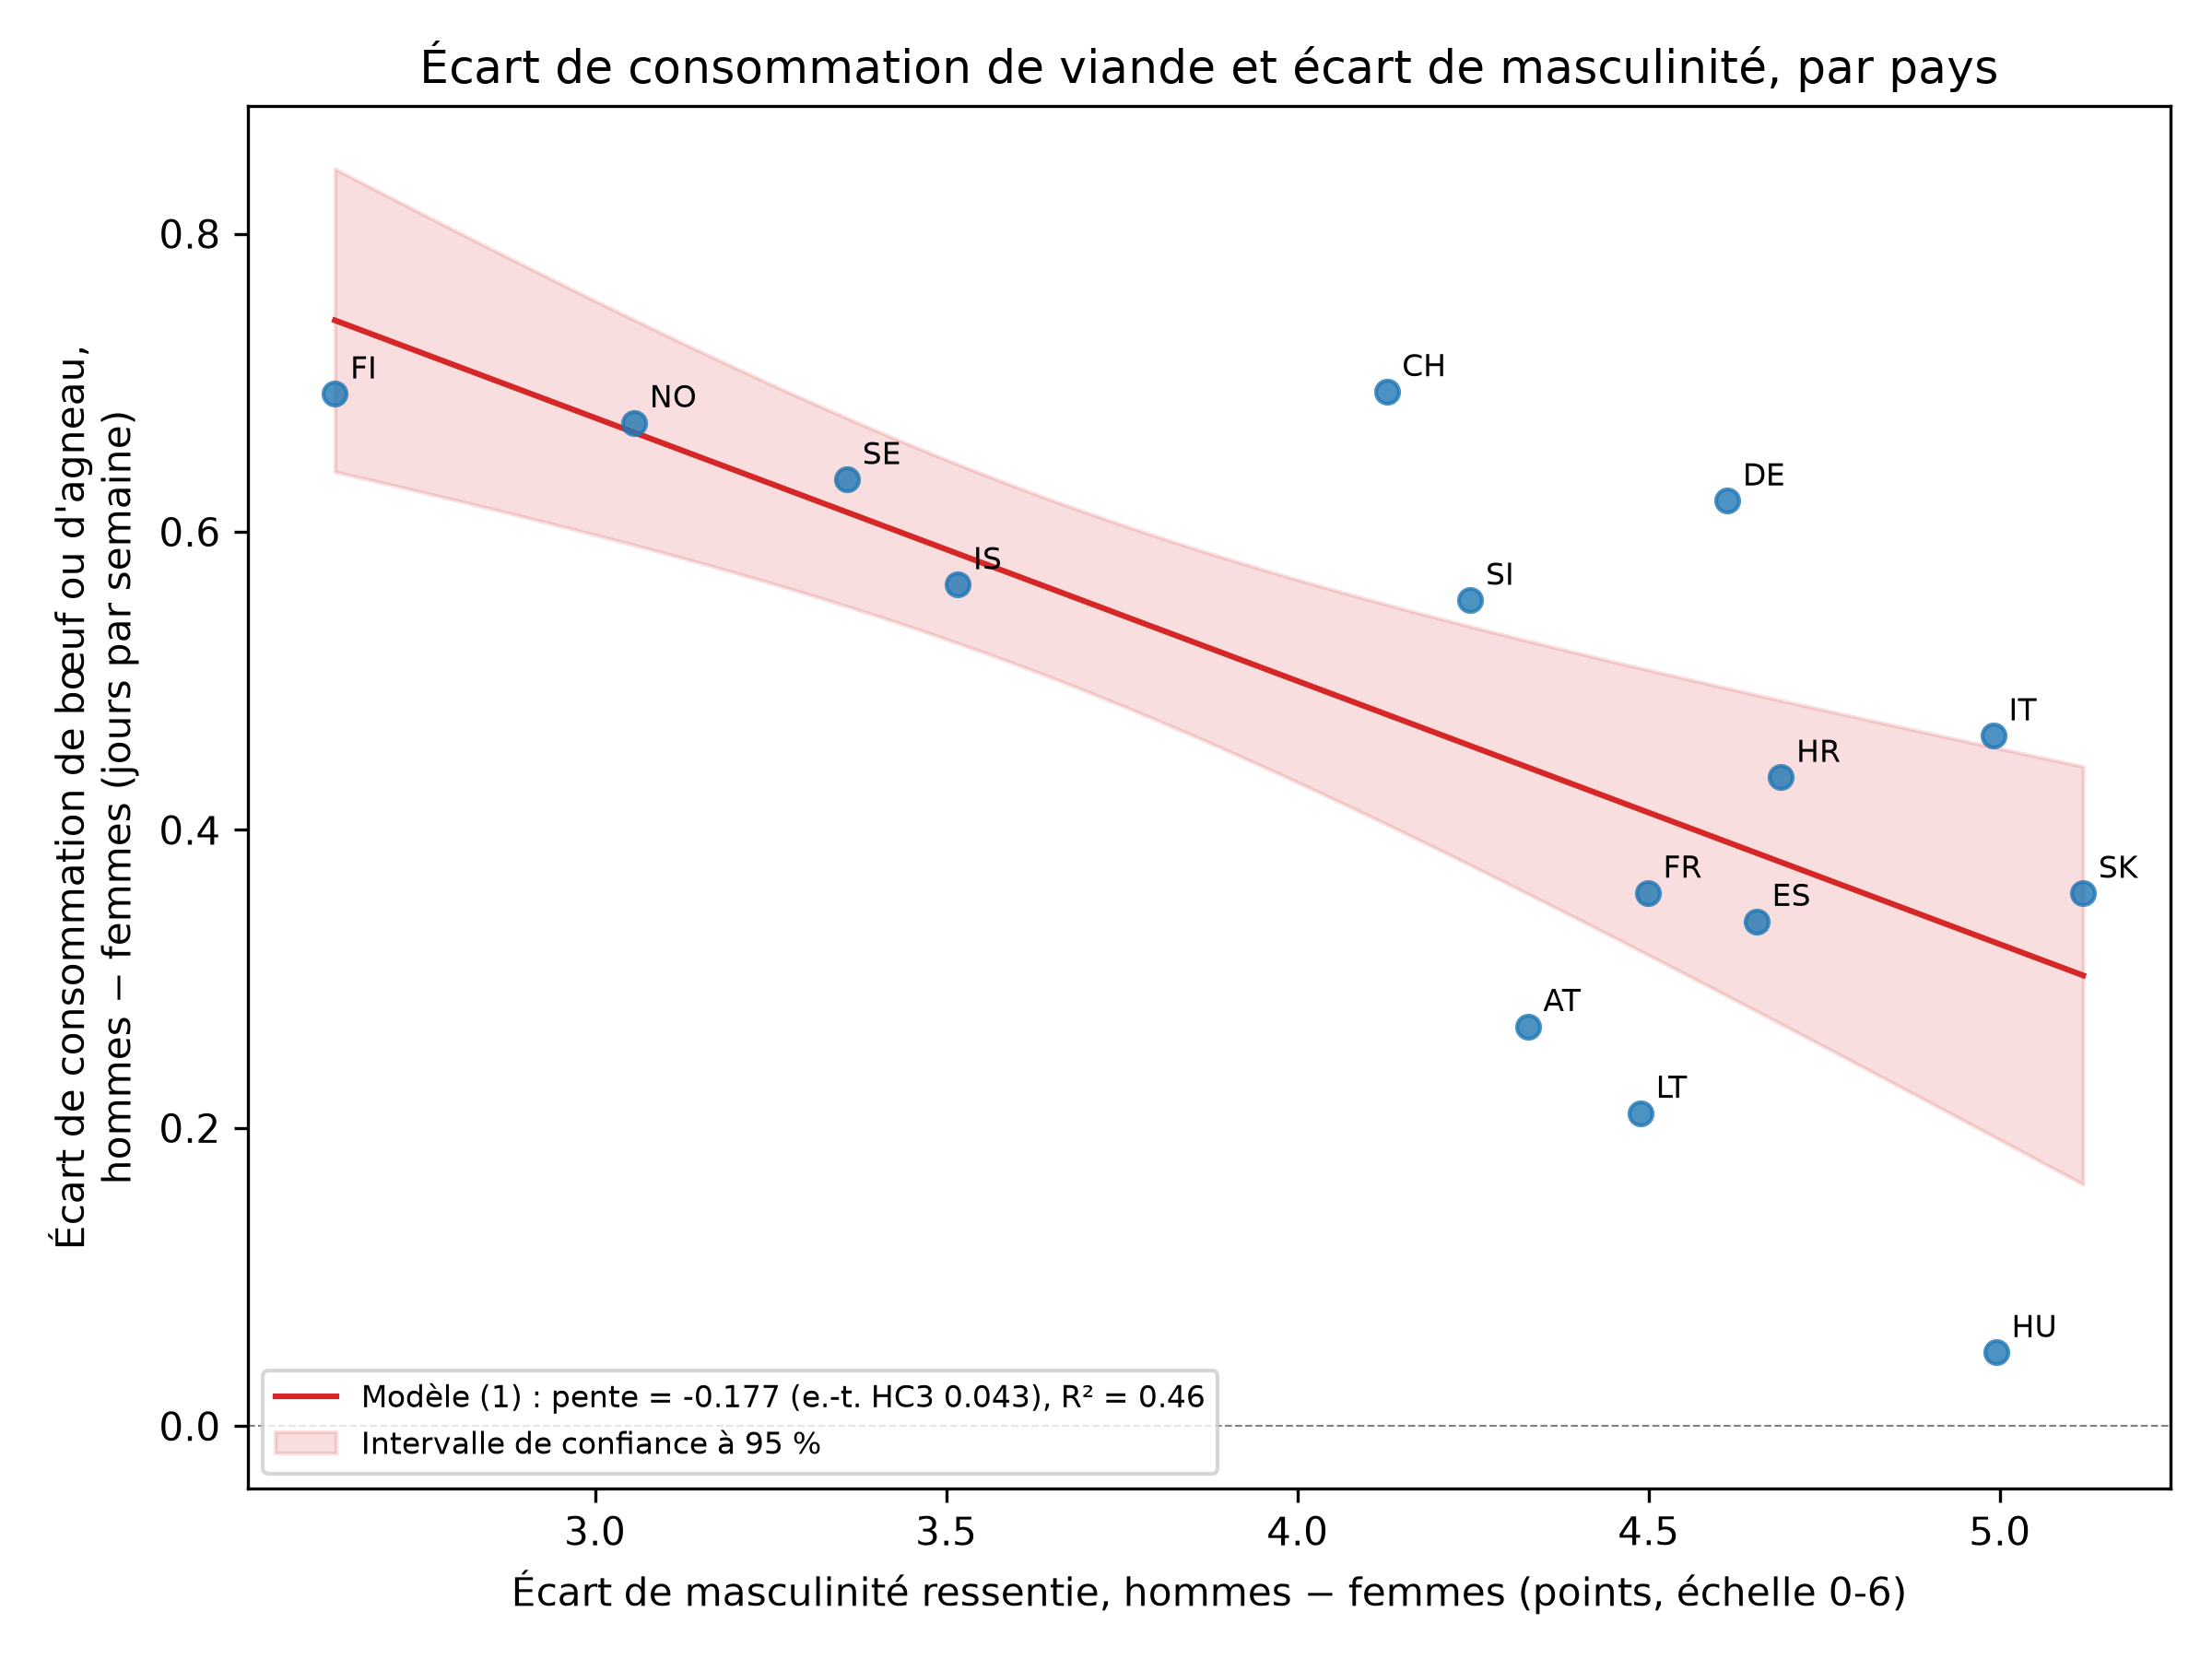

In [ ]:
afficher_sortie("nuage_ecarts.png")

**Lecture des résultats:** Le nuage de points montre une relation **négative** : les pays où hommes et femmes
se sentent le plus différents en masculinité sont ceux où l'écart de consommation de viande rouge est le plus faible.
Les pays nordiques (Finlande, Norvège, Suède, Islande) combinent un écart de masculinité modéré et un fort écart
de consommation, tandis que la Hongrie, la Lituanie ou l'Autriche présentent l'inverse.

Dans le modèle (1), sans contrôle, $\hat\beta = -0{,}177$ (erreur-type 0,043), significatif au seuil de 1 % :
un point d'écart de masculinité supplémentaire est associé à un écart de consommation inférieur de 0,18 jour par
semaine. L'écart de masculinité explique à lui seul 46 % de la variance entre pays ($R^2 = 0{,}458$).

Dans le modèle (2), qui contrôle le log du PIB par habitant en PPA, le coefficient tombe à $\hat\beta = -0{,}115$
(erreur-type 0,059). Il reste significatif au seuil de 10 %, mais de justesse ($p = 0{,}051$), ainsi il est fort probable qu'un léger changement
de l'échantillon ou de la spécification suffirait à faire passer ce seuil dans un sens ou dans l'autre. Le PIB n'est pas significatif ($\hat\gamma = 0{,}274$, $p = 0{,}18$),
et le modèle explique 54 % de la variance. 

### 5.3 Contrôle par le PIB

Le contrôle par le PIB réduit le coefficient d'environ un tiers (de −0,177 à −0,115). Cette baisse s'explique par
la matrice de corrélation : l'écart de masculinité est corrélé négativement au log du PIB (−0,63), lequel est
lui-même corrélé à l'écart de consommation (0,65). Concrètement, les pays les plus riches de l'échantillon, en particulier les pays
nordiques et la Suisse, ont à la fois des identités de genre moins polarisées et des écarts de consommation plus marqués.

Une fois les deux variables introduites ensemble, le PIB n'est pas significatif et l'écart de masculinité ne l'est
qu'au seuil de 10 %, alors que leur pouvoir explicatif conjoint reste élevé ($R^2 = 0{,}54$). Avec 15 pays et deux
régresseurs liés, les données contiennent peu de cas « discordants » (pays riches à fort écart de masculinité, ou
l'inverse) pour séparer leurs effets. 

Plusieurs lectures restent compatibles avec ces chiffres. La richesse peut être un **facteur de confusion**, qui
réduit la polarisation des identités de genre et augmente par ailleurs l'écart de consommation. Elle peut aussi agir
**en amont**, en faisant évoluer les normes de genre qui façonnent à leur tour les pratiques alimentaires, auquel cas
le contrôle masque une partie du rôle de la masculinité. Enfin, l'écart est mesuré en jours : il augmente
mécaniquement avec le niveau de consommation, plus élevé dans les pays riches. Le PIB capterait alors en partie un
**effet de niveau** plutôt qu'un effet propre de la richesse.

Le choix de la mesure du PIB compte : avec le PIB en dollars courants, qui exagère les écarts de richesse entre pays,
le coefficient tombait à −0,094 et n'était plus significatif ($p = 0{,}13$). La PPA, plus adaptée pour comparer des
niveaux de vie, laisse à l'écart de masculinité une part plus importante de la relation. Cette sensibilité à la
mesure du contrôle confirme la fragilité du résultat.

### 5.4 Diagnostics

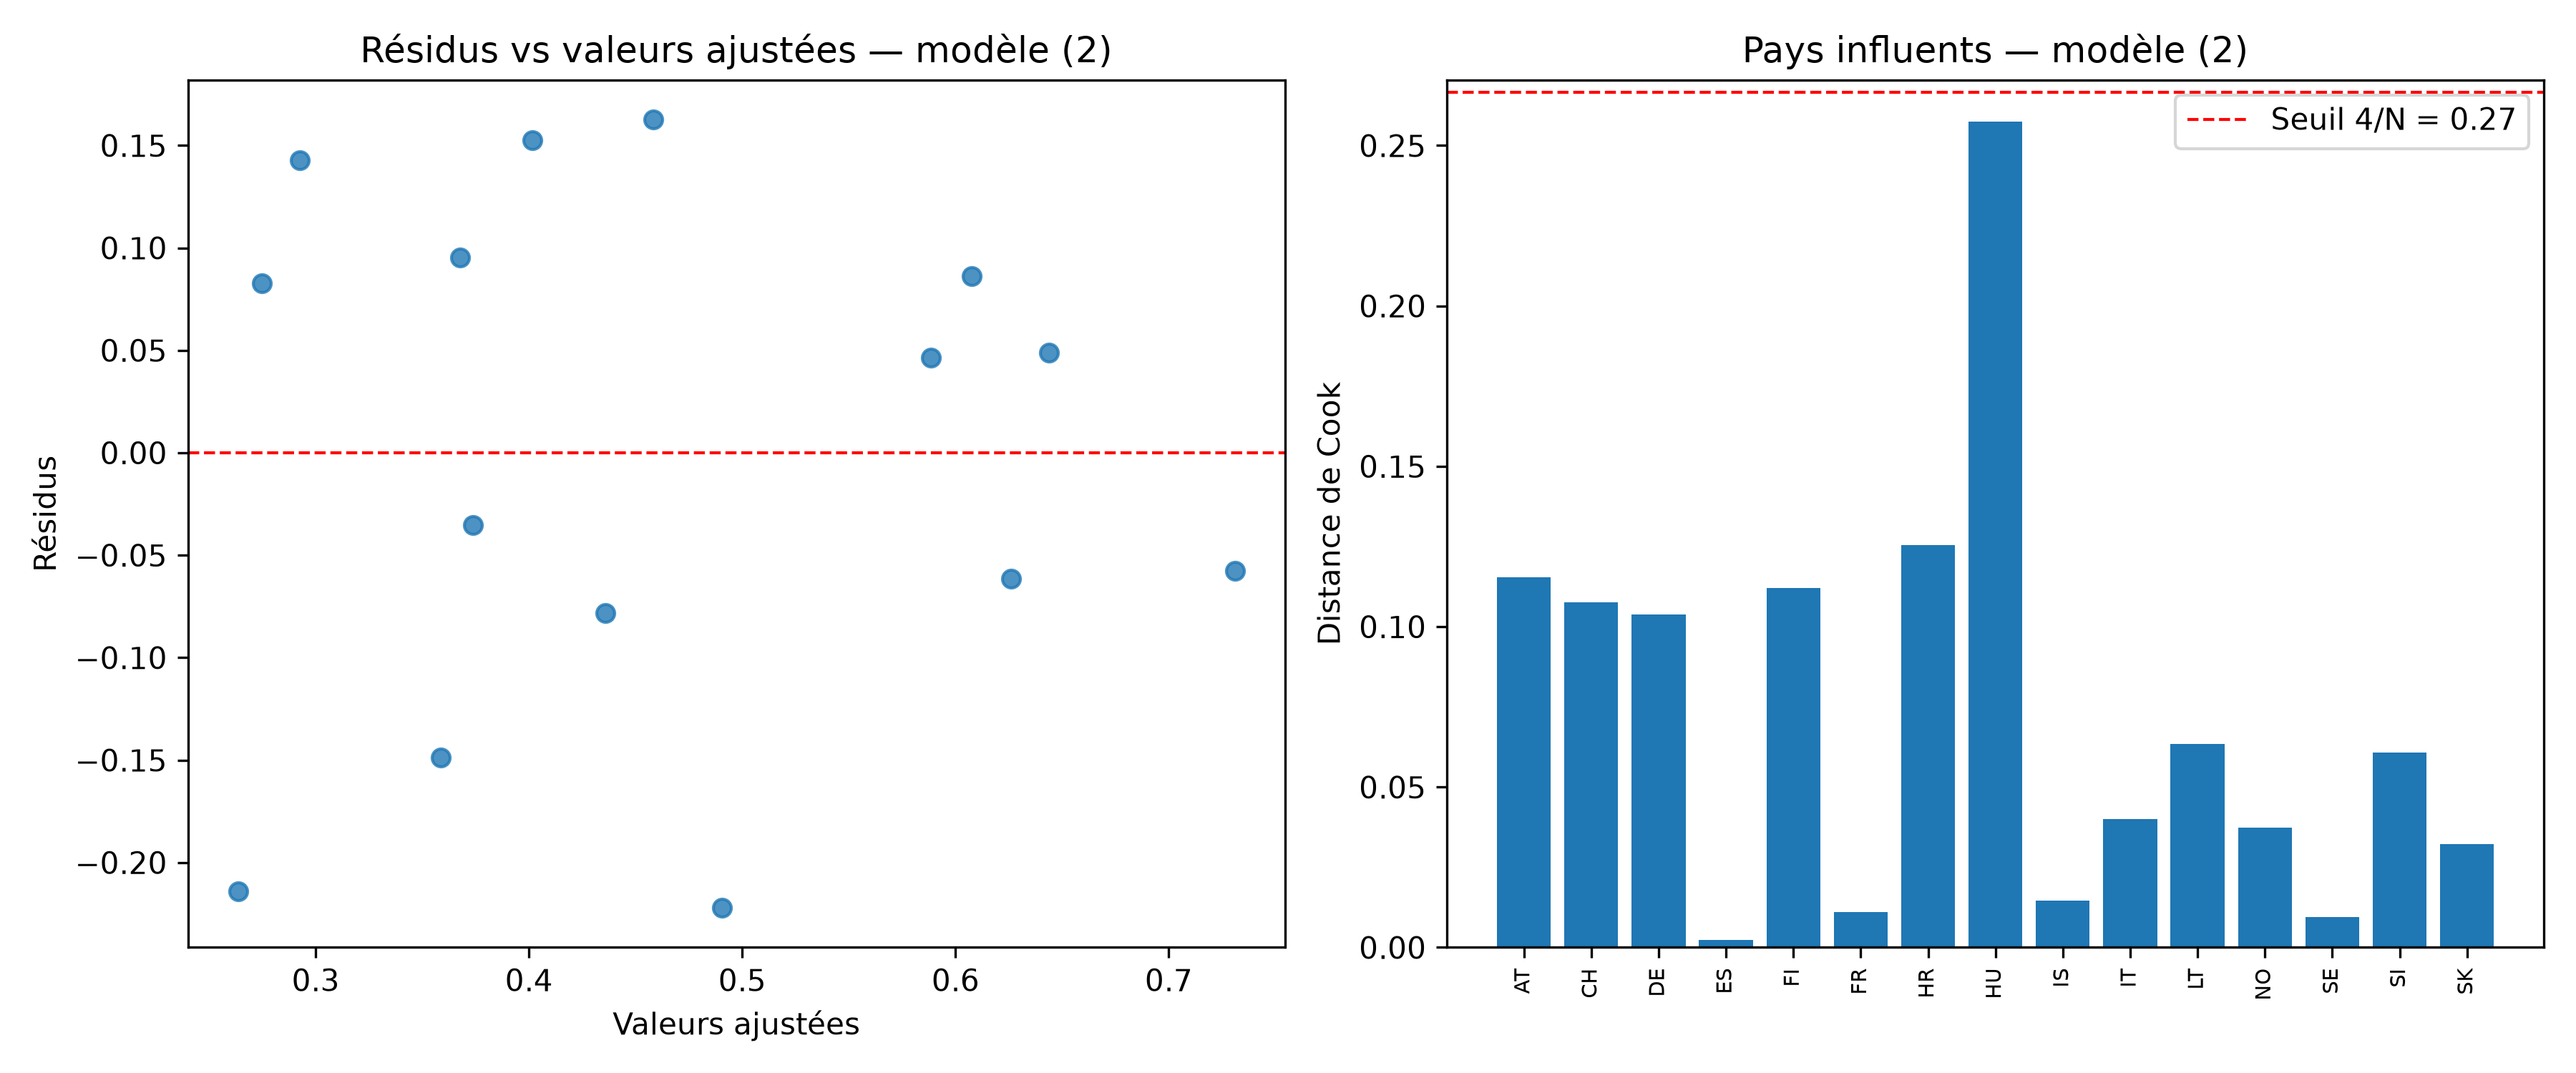

In [ ]:
# Résidus contre valeurs ajustées et distance de Cook par pays, modèle (2)
afficher_sortie("diagnostics.png", largeur=950)

**Lecture des diagnostics.** Les résidus du modèle (2) ne présentent pas de structure visible en fonction des
valeurs ajustées, ce qui ne suggère pas de forme fonctionnelle manifestement mal spécifiée ; avec 15 points,
ce diagnostic reste toutefois peu puissant. Aucun pays ne dépasse le seuil usuel de la distance de Cook
($4/N \approx 0{,}27$). La Hongrie, dont l'écart de consommation est quasi nul, s'en approche nettement plus que
les autres pays et reste l'observation la plus influente. La colinéarité entre les deux régresseurs reste modérée
(VIF de 1,66, très en dessous des seuils habituels de 5 à 10), si bien que l'imprécision des estimations du
modèle (2) tient davantage à la petite taille de l'échantillon qu'à une colinéarité sévère.

### 5.5 Interprétation

Entre les 15 pays étudiés, l'écart de masculinité ressentie entre hommes et femmes est **négativement** associé à
l'écart de consommation de viande rouge. Ce signe va à l'encontre de l'intuition selon laquelle des identités de
genre plus polarisées iraient de pair avec des pratiques alimentaires plus différenciées. Les données suggèrent donc un lien négatif entre
polarisation des identités de genre et écart de consommation, mais un lien fragile, qu'il est difficile de
distinguer du niveau de développement.

Ces résultats doivent être lus avec plusieurs réserves :
- **Association et non causalité** : il s'agit d'une corrélation entre moyennes nationales, qui ne dit rien des
  comportements individuels et ne permet pas d'identifier un effet causal.
- **Taille de l'échantillon** : 15 pays seulement, ce qui limite fortement la puissance des tests et rend les
  estimations sensibles à quelques pays, notamment le groupe nordique, ainsi qu'au choix de la mesure du PIB.
- **Mesure de la consommation** : la question de l'ISSP porte uniquement sur le bœuf et l'agneau, et compte des
  jours de consommation, pas des quantités. Les pays où l'on consomme surtout du porc ou de la volaille, tels que les pays de l'Est sont donc
  imparfaitement décrits, et l'écart exprimé en jours augmente mécaniquement avec le niveau de consommation.
- **Décalage temporel** : la consommation est mesurée surtout en 2020-2021 (ISSP) et la masculinité en 2023-2024
  (ESS 11), auprès de répondants différents.

## 6. Discussion et conclusion

### 6.1 Synthèse des résultats
Les statistiques descriptives confirment d'abord deux régularités nettes sur l'ensemble des 15 pays étudiés : les hommes déclarent systématiquement consommer du bœuf ou de l'agneau plus fréquemment que les femmes (écart positif partout, de $0{,}05$ à $0{,}69$ jour par semaine pour une moyenne de $0{,}46$ jour) et les identités de genre demeurent fortement différenciées (écart de masculinité ressentie compris entre $2{,}6$ et $5{,}1$ points sur une échelle de $0$ à $6$, moyenne de $4{,}2$). Toutefois, la comparaison géographique révèle que les niveaux de consommation varient davantage entre pays qu'entre sexes et que les pays nordiques (Finlande, Norvège, Suède, Islande) et la Suisse combinent les écarts de masculinité les plus modérés avec des écarts absolus de consommation parmi les plus élevés, à l'inverse de pays comme la Hongrie ou la Lituanie.

Au niveau agrégé, l'estimation par moindres carrés ordinaires met ainsi en évidence une association négative entre l'écart de masculinité ressentie et l'écart de consommation de viande rouge, à rebours de l'hypothèse d'une polarisation parallèle. Sans variable de contrôle, l'écart de masculinité explique près de la moitié de la variance entre pays ($\hat\beta = -0{,}177$, significatif au seuil de 1 %, $R^2 = 0{,}458$). L'introduction du logarithme du PIB par habitant en parité de pouvoir d'achat, qui varie d'un facteur d'environ $2{,}5$ dans l'échantillon, réduit toutefois le coefficient d'environ un tiers ($\hat\beta = -0{,}115$, $p = 0{,}051$, $R^2 = 0{,}54$), le maintenant à la lisière du seuil de 10 %. Bien que la colinéarité reste modérée ($\text{VIF} = 1{,}66$) et qu'aucun pays ne dépasse le seuil de distance de Cook (la Hongrie demeurant la plus influente), il reste difficile sur 15 pays de démêler un effet propre des normes de genre d'un effet de richesse ou de niveau de consommation, d'autant que le résultat perd sa significativité avec le PIB en dollars courants ($\hat\beta = -0{,}094$, $p = 0{,}13$).

### 6.2 Limites
- **Niveau d'analyse** : association entre pays ; aucune conclusion sur les individus (sophisme écologique).
- **Taille d'échantillon** : 15 pays, puissance statistique faible.
- **Mesure** : `mascfel` mesure une identité ressentie, indicateur approché des normes de genre.
- **Données déclaratives** et enquêtes menées à des dates différentes (ISSP 2020, ESS 11).
- **Causalité** : aucune relation causale ne peut être établie.

### 6.3 Pistes
Au-delà de ce cadre, l'analyse gagnerait à s'ouvrir à d'autres catégories alimentaires, par exemple en comparant par exemple la viande rouge à d'autres viandes ou à des régimes davantage tournés vers le végétal, et à croiser la masculinité ressentie avec d'autres dimensions culturelles, culinaires ou économiques, telles que les indicateurs d'égalité de genre ou les prix relatifs. Sur le plan économétrique, l'exploration de formes non linéaires, de termes d'interaction avec le niveau de vie, d'hétérogénéités intra-pays (selon l'âge, le milieu ou le statut socio-économique) et de plusieurs vagues d'enquêtes permettrait d'affiner la compréhension de ces écarts dans le temps et au sein des sociétés.

Une autre perspective consisterait à étudier la mise en scène publicitaire autour de la viande, après des tentatives sur Google Ads et Google Trends restées sans résultats exploitables en raison de filtres trop étroits et d'un sujet trop ciblé. Une collecte plus large combinant reconnaissance d'images et analyse par LLM pourrait produire un indicateur pertinent de l'usage de registres masculinistes, bien que sa mise en œuvre reste difficile avec les ressources techniques et les connaissances actuelles lorsque ces messages passent par des codes implicites ou ambigus.

<a id="sec-7"></a>
## 7. Annexe : reproductibilité

Ordre d'exécution depuis la racine du projet :

```bash
pip install -r requirements.txt
plotly_get_chrome            # Chrome pour l'export des cartes en PNG (voir README)
python Src/data_upload.py
python Src/import_clean.py
python Src/merge.py
python Src/stats_descriptives.py
python Src/maps.py
python Src/carte_masculinite.py
python Src/regression.py
```

`Src/data_upload.py` télécharge le PIB par habitant en PPA par l'API de la Banque mondiale (connexion internet
requise). S'il n'est pas lancé, `Src/merge.py` l'appelle automatiquement lorsque le fichier du PIB est absent.
Avec `RECALCULER = True` (section 1), le notebook relance lui-même ces scripts dans cet ordre.

In [ ]:
import importlib.metadata as md_
paquets = ["pandas", "numpy", "statsmodels", "plotly", "pycountry", "matplotlib", "kaleido"]
versions = {}
for p in paquets:
    try:
        versions[p] = md_.version(p)
    except md_.PackageNotFoundError:
        versions[p] = "non installé"
print("Python", sys.version.split()[0])
display(pd.Series(versions, name="version").to_frame())

Python 3.14.7


,version
pandas,3.0.6
numpy,2.5.5
statsmodels,0.15.0
plotly,7.1.0
pycountry,26.2.16
matplotlib,3.11.2
kaleido,1.5.2


In [ ]:
print("Fichiers produits dans Data/processed/ :")
for f in sorted(PROCESSED.iterdir()):
    if f.is_file():
        print(f"  {f.name:<45} {f.stat().st_size / 1e6:6.2f} Mo")

Fichiers produits dans Data/processed/ :
  ess11_agrege_pays.csv                           0.01 Mo
  ess11_nettoye.csv                               3.99 Mo
  issp_clean.csv                                  1.20 Mo
  issp_par_pays.csv                               0.00 Mo
  meta_ads_control_multilang_clean.csv            3.34 Mo
  meta_ads_meat_bbq_clean.csv                     3.15 Mo
  table_jointe.csv                                0.01 Mo
